<center><font size="+4">Programming & Data Analytics & AI 1 2025/2026</font></center>
<center><font size="+2">Sant'Anna School of Advanced Studies, Pisa, Italy</font></center>
<center><img src="https://github.com/EMbeDS-education/ComputingDataAnalysisModeling20242025/raw/main/PDAI/jupyter/jupyterNotebooks/images/sssaLEMBEDSdtu.png" width="900" alt="L'EMbeDS"></center>

<center><font size="+2">Course responsible</font></center>
<center><font size="+2">Andrea Vandin a.vandin@santannapisa.it</font></center>

---

<center><font size="+4">Module 2, Part 2</font></center>
<center><font size="+4">Lecture 5: Breast Cancer Diagnosis 3</font></center>
<center><font size="+4">Supervised learning: classification</font></center>

---

> __This notebook has been created by Dr Daniele Licari for previous editions of this course, and then further elaborated by Andrea Vandin__
> - __I thank Daniele for the great job in preparing the material__
> - __I also thank Daniele for collaborating on the design of PDAI 1 and 2 since their first editions/incarnations__

In [1]:
from IPython.display import Image, display

url_github_repo_basic="https://github.com/EMbeDS-education/ComputingDataAnalysisModeling20252026/raw/main/"
url_github_repo=url_github_repo_basic+"PDAI/"
url_images=url_github_repo+'jupyter/jupyterNotebooks/images/'

The first time you run this notebook, you need to download a python library we prepared
- pdai_utils.py

In [2]:
import urllib.request
from pathlib import Path
url=url_github_repo+'jupyter/jupyterNotebooks/pdai_utils.py'
print('Downloading PDAI library from',url)
urllib.request.urlretrieve(url,Path(url).name)

('pdai_utils.py', <http.client.HTTPMessage at 0x1069576f0>)

**This notebook provides an overview to the supervised learning pipeline**

We are going to:
   * use the Scikit-learn library for classification task
   * understand how to evaluate the performance of classifiers
   * discuss the problem of model overfitting.
   * discuss how to tune the hyperparameters and model validation

This notebook presents Python programming examples for supervised machine learning: 
- splitting data, predictive models, decision boundary, evaluation, cross-validation, hyperparameters tuning.  

You can find more details in the [APPENDIX](#APPENDIX) of this document.

**References** 
This notebook is mainly based on the following books:

* <mark>[Statistics and Machine Learning in Python, E.Duchesnay, T.Löfstedt, F.Younes](ftp://ftp.cea.fr/pub/unati/people/educhesnay/pystatml/StatisticsMachineLearningPythonDraft.pdf)</mark>
* <mark> [Statistical Learning & Large Data, Francesca Chiaromonte](https://github.com/EMbeDS-education/StatsAndComputing20222023/wiki/SLLD)</mark>
* [Python for Data Analysis, 2nd edition, William Wesley McKinney (O’Reilly)](https://www.oreilly.com/library/view/python-data-science/9781491912126/)
* [Freely available Jupyter notebooks covering the examples/material of each chapter](https://github.com/jakevdp/PythonDataScienceHandbook/tree/master/notebooks)
* [Introduction to Data Mining (2nd Edition), Pang-Ning Tan et al.](https://www.cse.msu.edu/~ptan/)
* [Introduction to Machine Learning Algorithms, KNIME AG](https://www.knime.com/knime-course-material-download-page)

Some pictures have been taken from these sources. 

Read the step-by-step instructions below carefully. To execute the code, click on the corresponding cell and press the SHIFT-ENTER keys simultaneously.

In [3]:
print('https://www.youtube.com/watch?v=iDQz6FBpxZA')

https://www.youtube.com/watch?v=iDQz6FBpxZA


In [ ]:
from IPython.display import HTML 
#  A Gentle Introduction to Classification Models
HTML('<iframe width="860" height="515" src="https://www.youtube.com/embed/iDQz6FBpxZA" title="YouTube video player" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture" allowfullscreen></iframe>')

# A Visual Introduction to Decision Trees
Supervised learning models try to learn the relationship between 
- measured features _X_ of data and 
- some target labels _y_ associated with the data. 

Supervised learning models divide in depending on the _type_ of _y_:
- *Classification* tasks, when the labels contain _discrete_ values
- *Regression* tasks, when the labels contain _continuous_ values. 

The following interactive example was written by Stephanie and Tony on R2D3.
- It discusses a machine learning model to distinguish homes in New York from those in San Francisco. 
- It introduces you to the notions of 
  - decision boundary, 
  - decision tree, 
  - training and test set
  - evaluation of a model, and overfitting.

In [5]:
from IPython.display import display, HTML,IFrame 
url_visual_intro="http://www.r2d3.us/visual-intro-to-machine-learning-part-1/"
print(url_visual_intro)
IFrame(src="http://www.r2d3.us/visual-intro-to-machine-learning-part-1/", width=1224, height=550) # doesn't work on colab

http://www.r2d3.us/visual-intro-to-machine-learning-part-1/


## Preliminary: Gini impurity measure

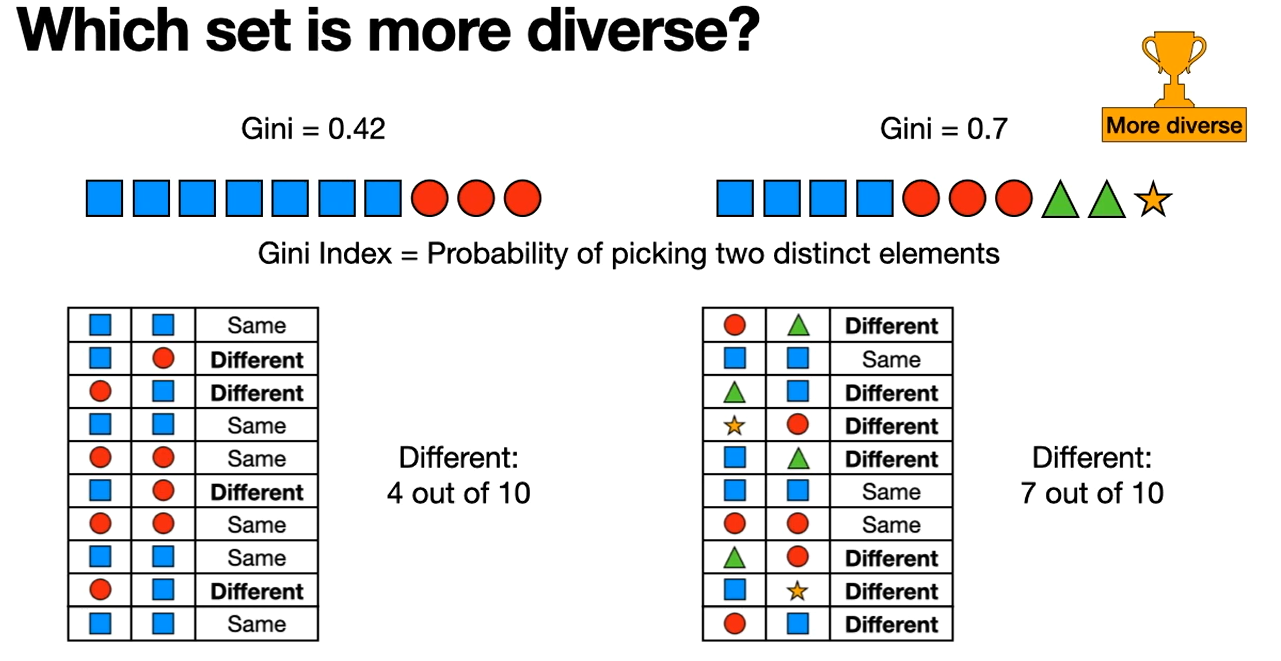

image from https://youtu.be/u4IxOk2ijSs?t=65


In [6]:
display(Image(url_images+'gini.png'))
print('image from https://youtu.be/u4IxOk2ijSs?t=65')

The Gini impurity measure allows, in fact, to measure how impure is a dataset
- Impure refers to the probability that, by taking 2 elements from a set, we get two _different_ elements
  - Different might mean, e.g., points with different label (benign/malignant)

This measure is used in the classifier model we present in this class: classifier trees

What does it means: __probability__ that, by taking __2 elements__ from a set, we get __two _different___ elements?
  - In the picture above, we estimate these probabilities as
    - Left: 4/10
    - Right: 7/10
  - Mathematically, we can compute this as:
      - Prob 1 circle: num-circles/num-elements = `P(c)`
        - Prob 2 circles: `P(c)*P(c)`
      - Prob 1 square: num-squares/num-elements = `P(s)`
        - Prob 2 squares: `P(s)*P(s)`    
      - __Prob 1 circle, 1 square: `1 - P(c)*P(c) - P(s)*P(s)`__

More details on how to calculate the gini index for a decsion tree: 
- https://youtu.be/7VeUPuFGJHk?t=428

# Classification of Benign and Malignant Breast Cancer 
We will first take a look at a simple classification task for our breast cancer dataset of reference
- If you don't remember: look at the material from the previous 2 classes


**Classification Task**

Given a new (tabular/textual representation of a) biopsy of a breast cancer (a new row corresponding to a new biopsy image), 
- we want to predict whether it is
  - benign or 
  - malignant

## Load libraries

In [7]:
# Data Processing libs
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Visualizzation libs
# keeps the plots in one place. calls image as static pngs
%matplotlib inline
import matplotlib.pyplot as plt # side-stepping mpl backend
from IPython.display import display, Markdown # display Markdown code using Python
import seaborn as sns # data visualization library based on matplotlib

from warnings import filterwarnings
filterwarnings('ignore')

#Not necessary anymore
# # download the all repository if you are on COLAB
# import os
# import sys
# IN_COLAB = 'google.colab' in sys.modules
# course_name = 'StatsAndComputing20222023' 

# if IN_COLAB: 
#     !git clone https://github.com/EMbeDS-education/{course_name}.git
#     os.chdir(f'/content/{course_name}/PDAI/jupyter/jupyterNotebooks') #for SSSA
#     # os.chdir(f'/content/{course_name}/jupyter/jupyterNotebooks')

In [8]:
#%pip install -U jinja2
import jinja2

## Load data
Let us 
- load the data preprocessed in the class on preprocessing and EDA
- separate it into *Features matrix* and *Target array*

Remember: in the preprocessing analysis we have:
- dropped 12 extreme outliers
- dropped all `radius` and `perimemter` columns as the are highly correlated with the corresponding `area` ones

We are left with
- 557 observations/rows
- 24 columns
  - 23 features
  - 1 target (`target`)

In [9]:
#load dataset, we will first load the data into a Pandas DataFrame object and display its content

data = pd.read_csv('data/WBCD_preprocessed.csv')
#If you prefer to use the one generated by the professor during the class
#data = pd.read_csv(url_github_repo+'jupyter/jupyterNotebooks/data/WBCD_preprocessed.csv')

df_X = data.iloc[:,:-1] # Features matrix
#df_y = data.iloc[:,-1] # Target array
df_y = data[['target']] # Target array
data.head()

,mean texture,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,texture error,area error,...,symmetry error,fractal dimension error,worst texture,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,10.38,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,0.9053,153.40,...,0.03003,0.006193,17.33,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,17.77,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.7339,74.08,...,0.01389,0.003532,23.41,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,21.25,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7869,94.03,...,0.02250,0.004571,25.53,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,14.34,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7813,94.44,...,0.01756,0.005115,16.67,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant
4,15.70,477.1,0.12780,0.17000,0.1578,0.08089,0.2087,0.07613,0.8902,27.19,...,0.02165,0.005082,23.75,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,malignant


Now, it is the time to __use__ the target variable `y`
- We must encode it!

In [10]:
# Encode target labels with value 1 for malignant and 0 for benign
dict_lb_to_num = {'malignant': 1, 'benign':0} 
df_y = df_y.replace(dict_lb_to_num)
df_y.value_counts()

target
0         352
1         205
Name: count, dtype: int64

## Splitting Data

Before _training_ our model, we need to 
- prepare the data so to be able, later on, to evaluate how well we trained the model
- we want to be able, a posteriori, to evaluate the _quality_ of our model: how good is it in its classification task on new unseen data?

This **evaluation must be on data that the model has not seen before**,
- We must split the data into a _training_ set and a _testing_ set. 
  1. *Training dataset*: Large portion of the dataset used to fit/train/parameterize the model
  1. *Test dataset (holdout set)*: Small portion of the dataset to provide an unbiased evaluation of a trained model fit on the training dataset
     - You must not use any information from the test set when training (or before)
     - Not even to scale the data!

We hold back a subset of the data from the original dataset, and then use this to check the model performance. 
- But not any randomly drawn subset. We must properly select it...

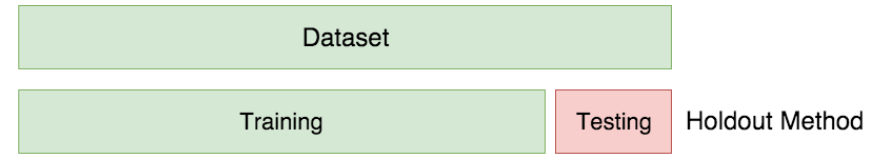

In [11]:
display(Image(url_images+'splitting_1.png'))

**We usually split the data around 70%-30% (or 80%-20%) between training and testing sets.**


In [12]:
%%html
<marquee style='width: 30%; color: red;'><b>Important! Golden Rules</b></marquee>

Just to be sure you understood :D
- Never use testing data for fitting an estimator
  - Do not do it in any form! Not even indirectly (e.g., to decide how to scale the training set)
- Use testing data only for evaluation (please don't touch the testing set)
  - Do not touch the testing set

<!-- <img src='images/training_2.jpg' width='500px'> -->

<div class="alert alert-block alert-warning" style='color:black'>
    
Some datasets present a large imbalance in the distribution of target classes. <b>It is important to have the same distribution of label values across test and training set.</b>
- You can obtain this using <b>stratified sampling</b> to ensure that relative class frequencies is approximately on both sets.

</div>

In [13]:
df_y

,target
0,1
1,1
2,1
3,1
4,1
...,...
552,1
553,1
554,1
555,1


target
0         0.631957
1         0.368043
Name: proportion, dtype: float64


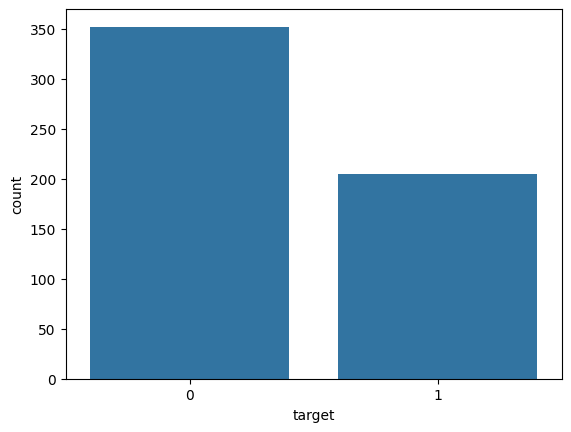

In [14]:
sns.countplot(data=df_y,x='target')
print(df_y.value_counts(normalize=True))


[*sklearn.model_selection.train_test_split(*arrays, test_size=None, train_size=None, random_state=None, shuffle=True, stratify=None)*](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html):
SplitS arrays or matrices into random train and test subsets

In [15]:
from sklearn.model_selection import train_test_split


# data is splitted 70%-30% in a stratified method on the class labels. 
X_train_raw, X_test_raw, y_train, y_test = train_test_split(df_X, df_y, test_size =.3, stratify=df_y, random_state=1) 

print(f"N. Training sample {len(y_train)}, {len(y_train)/len(df_y)*100:.2f}%")
print(f"N. Testing sample {len(y_test)}, {len(y_test)/len(df_y)*100:.2f}%")

y_train

N. Training sample 389, 69.84%
N. Testing sample 168, 30.16%


,target
279,0
197,1
527,0
223,1
370,0
...,...
249,1
278,0
334,0
260,0


As promised, we preserve about the same distribution of target labels in the training/test sets


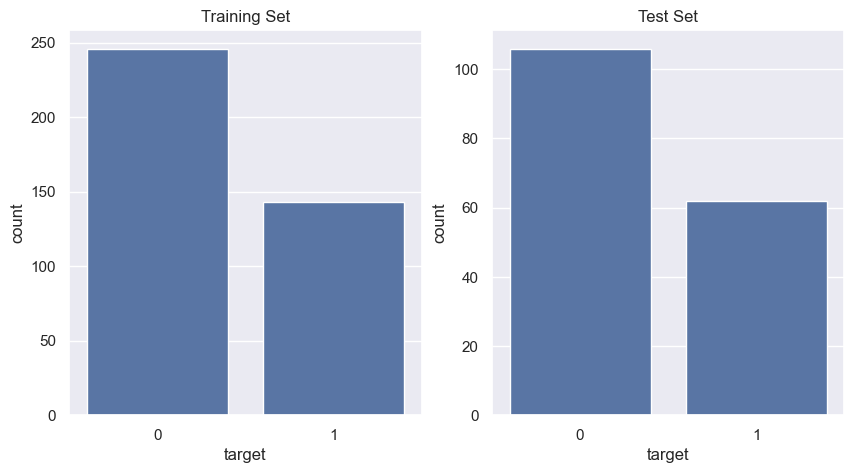

In [16]:
print('As promised, we preserve about the same distribution of target labels in the training/test sets')

# plot target distributions of test and training set
sns.set_theme(style="darkgrid")
fig = plt.figure(figsize = (10,5))
plt.subplot(1, 2, 1)
ax = sns.countplot(y_train.sort_values(by='target'),x='target')   
ax.set_title("Training Set")
plt.subplot(1, 2, 2)
ax = sns.countplot(y_test.sort_values(by='target'),x='target') 
ax.set_title("Test Set")
plt.show()

### Scaling VS Splitting training/test
If you need to scale your data, you shall use the `StandardScaler` in this way:
* `StandardScaler.fit_transform()` on train set 
   - we learn the parameters of scaling (means and standard deviations) on the train data 
   - we scale it
* `StandardScaler.transform()` on test set 
   - we do not want to learn anything from the test set!
   - we only scale it, based on the scaling parameters learned on the train data 

**Our models do not have to rely on parameters learned from the test set**

Including the test dataset in the `transform` computation will allow information 
- To flow from the test data to the train data. 
- Therefore, this information will flow to the model that learns from it, thus allowing the model to cheat (introducing a bias). 


In [17]:
from sklearn.preprocessing import StandardScaler #for Scaling the features

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw) # computes std and mean of each feature and scaling. 
X_test  = scaler.transform(X_test_raw)  # scales the test data.

Where the scaling parameters stored!?
- In the attributes of `scaler!`
- Ah, the beauty of OOP :D

Nice, but...
- do you remember what happens under the hood when scaling!?

In [18]:
# # # Standard Scaler - under the hood

# # # fit only on training
x_train_mean = X_train_raw.mean()
x_train_std = X_train_raw.std()

# # # transform training
X_train_raw = (X_train_raw-x_train_mean)/x_train_std

# # # transform testing
(X_test_raw-x_train_mean)/x_train_std

print('Standard Scaler on train/test set - under the hood')

Standard Scaler on train/test set - under the hood


In [19]:
print('https://www.youtube.com/watch?v=6Ry914HqeHI')

https://www.youtube.com/watch?v=6Ry914HqeHI


In [ ]:
from IPython.display import HTML 
#  Learning, predicting, and evaluating a Classifier
HTML('<iframe width="860" height="515" src="https://www.youtube.com/embed/6Ry914HqeHI" title="YouTube video player" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture" allowfullscreen></iframe>')

## Supervised Models in scikit-learn
The basic recipe for applying a supervised machine learning model:

0. Split training/test data
1. Choose a class of model

  <del>2. Choose best model hyperparameters </del>(we will see later)

3. Fit the model to the training data
4. Evaluate the model by  predicting on test set
5. Use the model to predict labels for new data

[Sklearn contains several supervised machine learning models](https://scikit-learn.org/stable/supervised_learning.html).
- We use a Decision Tree Classifier which predicts the value of a target variable by learning simple decision rules (if-then-else) inferred from the data features

In [20]:
from sklearn.tree import DecisionTreeClassifier

# 1. instantiate model
model = DecisionTreeClassifier(random_state=42) 
# 3. fit model to data (training)
model.fit(X_train, y_train)   
# 4. predict on test set
y_pred = model.predict(X_test)             
y_pred[:10] 

array([0, 0, 1, 1, 0, 0, 1, 1, 0, 0])

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# 1. instantiate model
model2 = KNeighborsClassifier() 
# 3. fit model to data (training)
model2.fit(X_train, y_train)   
# 4. predict on test set
y_pred2 = model2.predict(X_test)             
y_pred2[:10]

In [ ]:
from sklearn.svm import LinearSVC
# 1. instantiate model
model3 = LinearSVC() 
# 3. fit model to data (training)
model3.fit(X_train, y_train)   
# 4. predict on test set
y_pred3 = model3.predict(X_test)             
y_pred3[:10]

## How can I evaluate a trained model?

Let's draw the decision boundary of Decision Tree Classifier trained on the training set

Plotting train and test set...


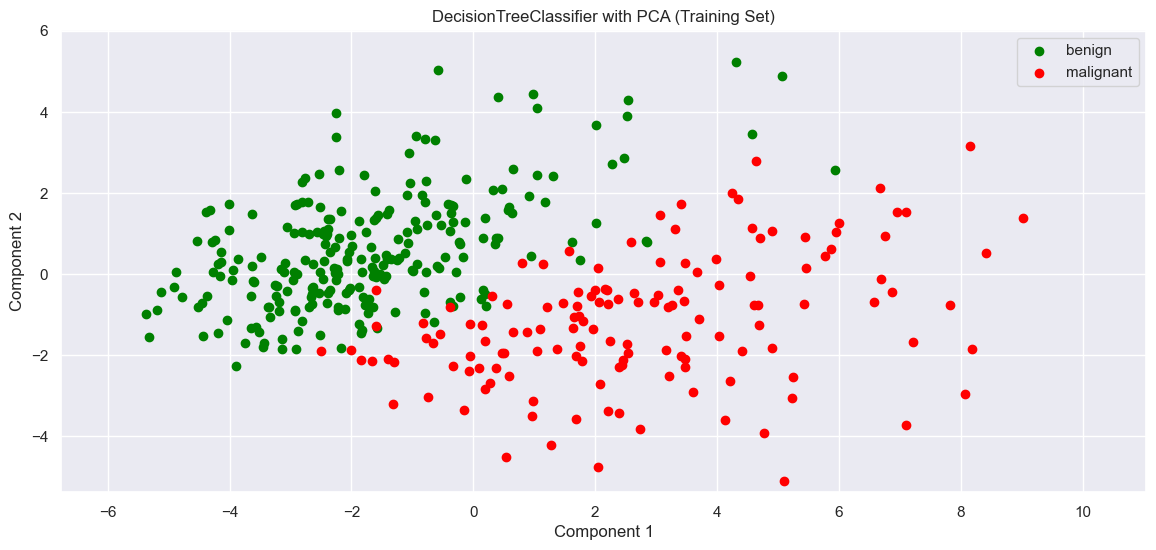

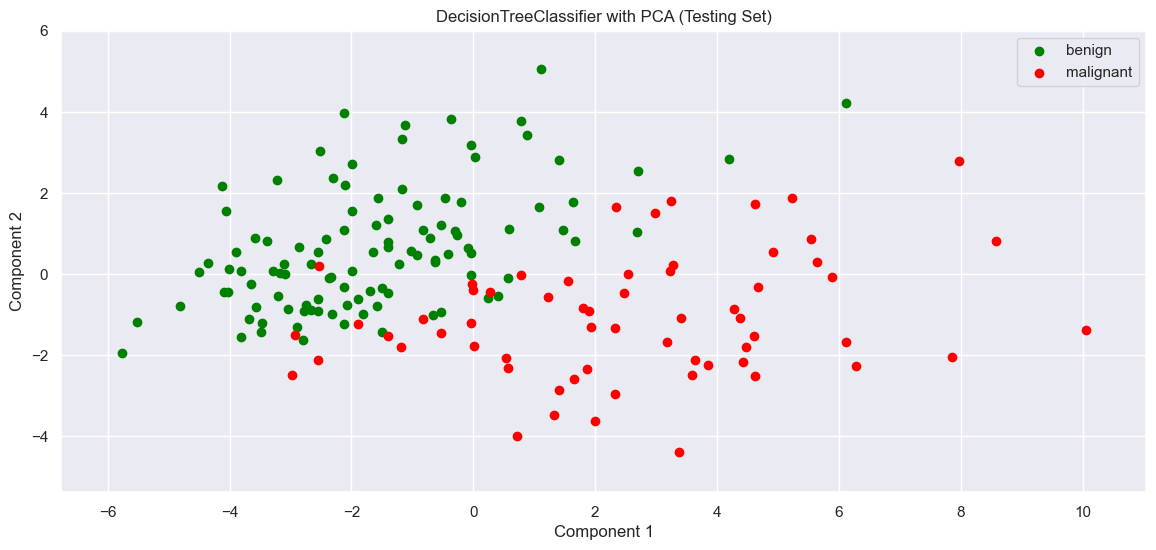

Plotting decision boundary on train and test set...


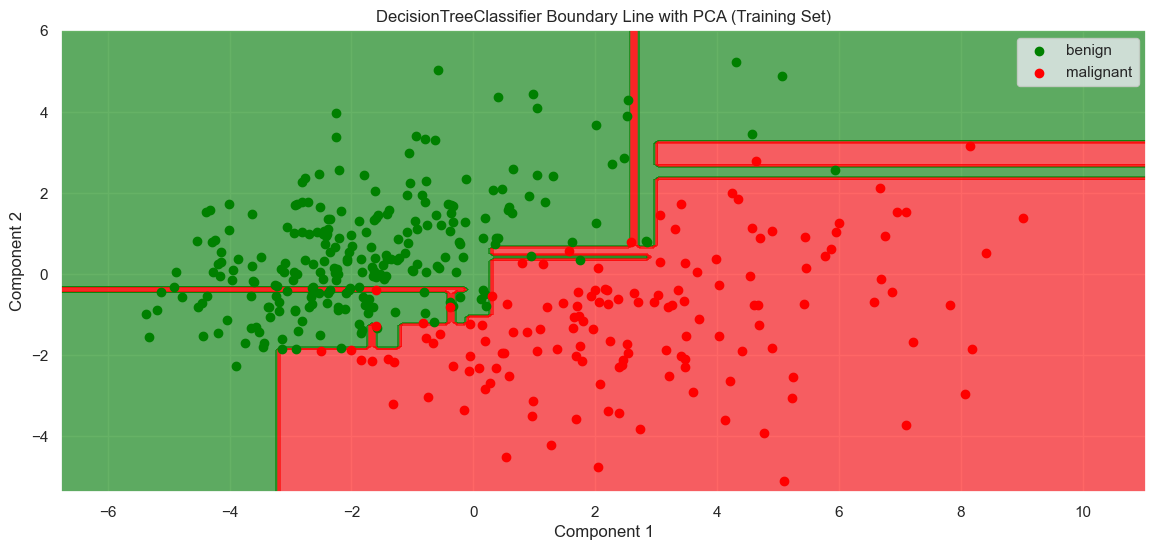

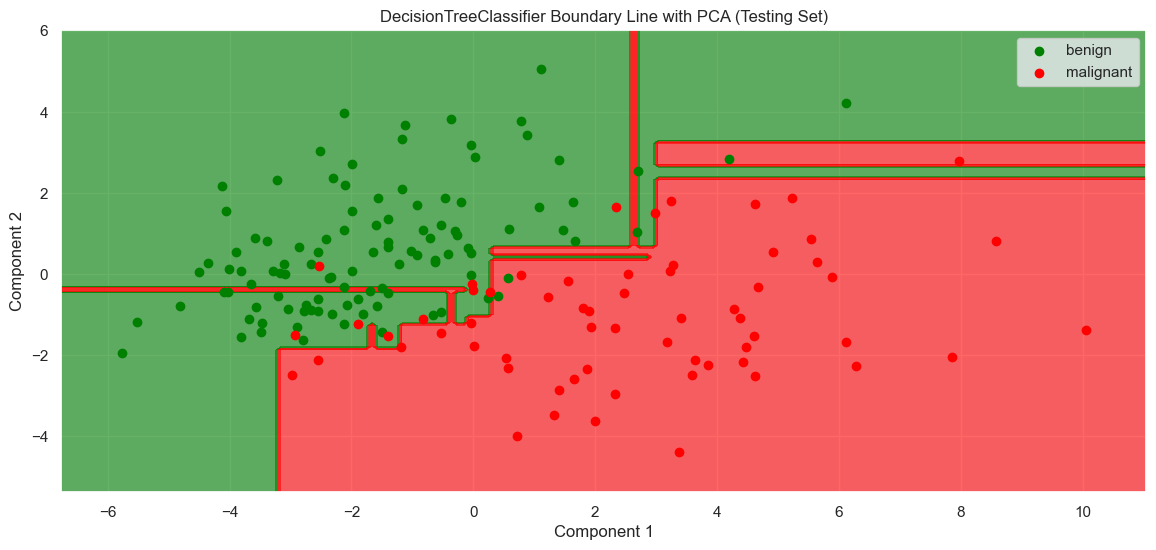

In [21]:
from pdai_utils import draw_boundary

# # draw decision boundary for visualization (and teaching) purpose
draw_boundary(DecisionTreeClassifier(random_state = 42),  X_train, X_test, y_train.target, y_test.target,verbose=1)


When we add new data (e.g. when we try to predict points from the testing set)
- The model might do mistakes. Actually, the model __will do__ mistakes
- This happened in the last plot above
    - where we evaluated classified the whole test set

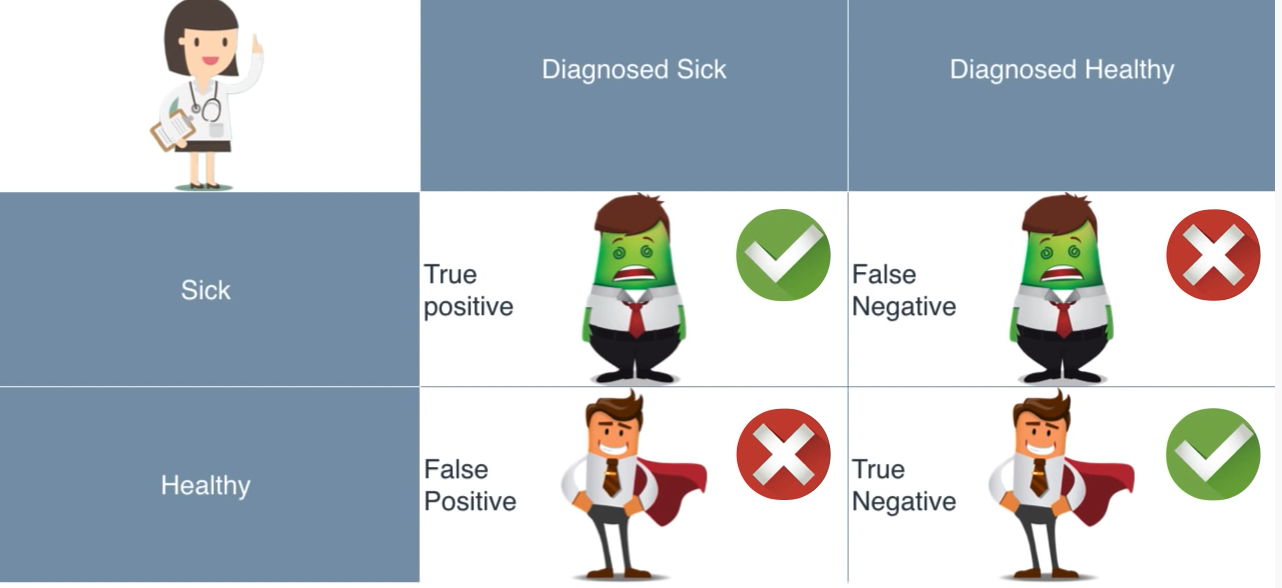

image from [Machine Learning: Testing and Error Metrics](https://www.youtube.com/watch?v=aDW44NPhNw0)


In [22]:
display(Image(url_images+'confusion_matrix_sick.png'))
print('image from [Machine Learning: Testing and Error Metrics](https://www.youtube.com/watch?v=aDW44NPhNw0)')

We can use the following metrics:
- *True Positive (TP)*  : Malignant cancer correctly identified as Malignant
- *True Negative (TN)*  : Benign cancer correctly identified as Benign
- *False Positive (FP)* : Benign cancer incorrectly identified as  Malignant
- *False Negative (FN)* : Malignant cancer incorrectly identified as Benign



The four outcomes can be formulated in a 2×2 confusion matrix

In [ ]:
display(Image(url_images+'confusion_matrix.png'))

* *Accuracy (ACC)*: (TP + TN) / (TP + FP + FN + TN)
* *Sensitivity (SEN)* or Recall of the positive class or true positive rate (TPR) or hit rate: SEN = TP / P = TP / (TP+FN)
* *Specificity (SPC)* or Recall of the negative class or true negative rate: SPC = TN / N = TN / (TN+FP)
* *Precision* or positive predictive value (PPV): PPV = TP / (TP + FP)

<!-- ![](https://miro.medium.com/max/700/1*kaqtNALKZujx1FGlbK11OQ.png) -->
In addition, *F1 Score* (or F-score) which is the harmonic mean of the precision and recall is usefull to deal with imbalaced datasets.
* *F1 = 2 * (precision * recall) / (precision + recall)*

__NOTE:__
Intuitively, 
- **precision** (on positive class) is the ability of the classifier **not to label as positive a sample that is negative**, 
- **recall** (on positive class) is the ability of the classifier to **find all the positive samples** (TPR).The F1 score penalizes the model more when Accuracy or Recall is low.

In [ ]:
display(Image(url_images+'evaluation.png'))
print('image from [Machine Learning: Testing and Error Metrics](https://www.youtube.com/watch?v=aDW44NPhNw0)')

display(Image(url_images+'credit_card_fraud.png'))

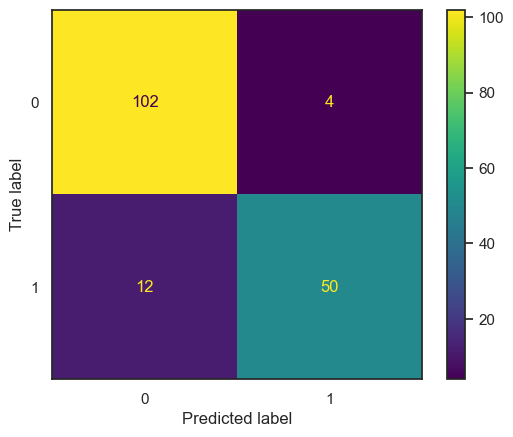

In [23]:
#from sklearn.metrics import plot_confusion_matrix, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report


sns.set(style="white")
#plot_confusion_matrix(model, X_test, y_test.target) 
# |TN|FP|
# |FN|TP|
#plt.show() 

predictions = model.predict(X_test)
cm = confusion_matrix(y_test, predictions, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=model.classes_)
disp.plot()

In [24]:
# Building a text report showing the main classification metrics.
print('='*20,'Training Set Results','='*20)
print(classification_report(y_train, model.predict(X_train)))

print('='*20,'Testing Set Results','='*20)
report_testing_dtree = classification_report(y_test, y_pred)
print(report_testing_dtree)
print('='*60)

==================== Training Set Results ====================
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       246
           1       1.00      1.00      1.00       143

    accuracy                           1.00       389
   macro avg       1.00      1.00      1.00       389
weighted avg       1.00      1.00      1.00       389

==================== Testing Set Results ====================
              precision    recall  f1-score   support

           0       0.89      0.96      0.93       106
           1       0.93      0.81      0.86        62

    accuracy                           0.90       168
   macro avg       0.91      0.88      0.89       168
weighted avg       0.91      0.90      0.90       168



[sklearn.metrics.classification_report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html): 
- Text summary of the precision, recall, F1 score for each class. 
- The support is the number of occurrences of each class in y_train or y_test.
- The reported averages include macro average (averaging the unweighted mean per label) and weighted average (averaging the support-weighted mean per label)



<div class="alert alert-block alert-warning" style='color:black'>


<b>In our case, the value of Recall of positive class (SEN) is considered a primary value, as the goal is to identify all cases of really positive (malignant tumor) minimizing false negative (e.g. I predict benign tumor but the patient has a malignant tumor)</b>. The malignant '1' tumors have positive class and those benign '0' negative class.
False positive (Malignant cancer incorrectly identified as Benign) can be identified by further investigation by doctors.
</div>

Saving tree in file plot_tree.pdf


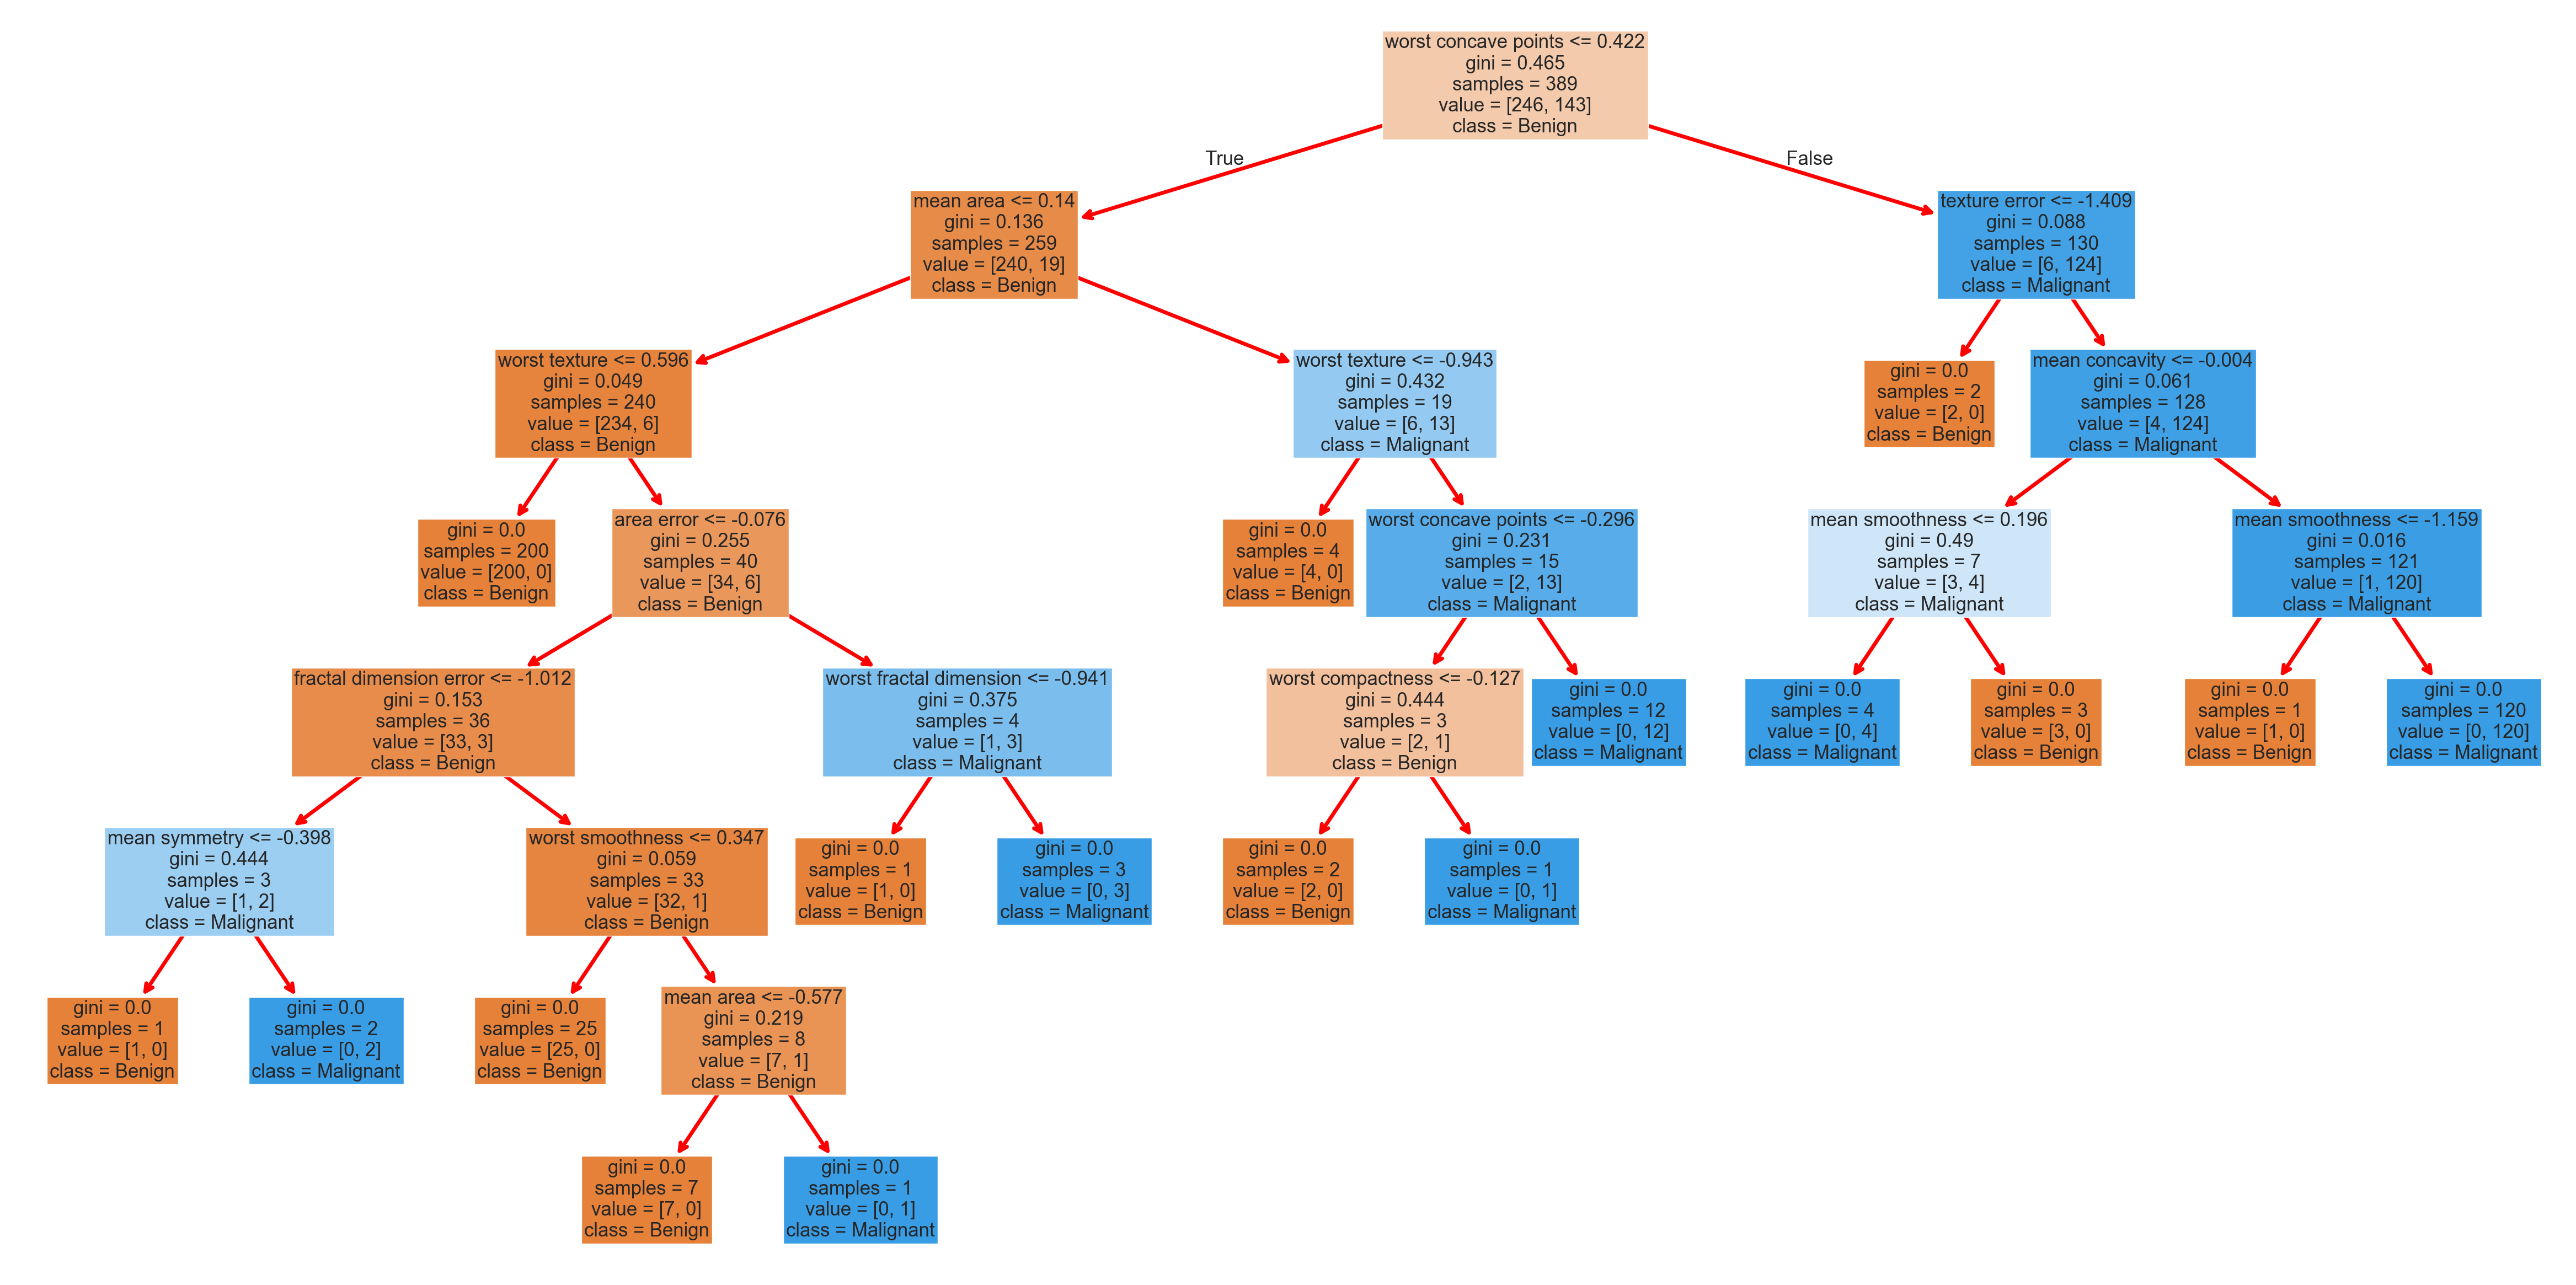

In [25]:
from pdai_utils import plot_decision_tree
plot_decision_tree(model, X_train, y_train, df_X.columns)

In [ ]:
# # 1. instantiate model
# model = DecisionTreeClassifier(random_state=42) 

# # 2. remove outliers
# X_train_no_outliers = X_train[(np.abs(X_train)<3).all(axis=1)]
# y_train_no_outliers = y_train[(np.abs(X_train)<3).all(axis=1)]
# print("How many outliers?",len(X_train_raw)-len(X_train_no_outliers))

# # 3. fit model to data (training)
# model.fit(X_train_no_outliers, y_train_no_outliers)   
# # 4. predict on new data 
# y_pred = model.predict(X_test) 

# # 5. evaluation
# print('='*5,'Testing Set Results (No Outliers in Training)','='*5)
# print(classification_report(y_test, y_pred))
# print('='*60)

## Random Forest

---
`The anecdote of the Wisdom of the crowd.` 
- At a 1906 country fair in Plymouth, 800 people participated in a contest to estimate the weight of an ox. 
- Nobody won the contest
- However, the statistician Francis Galton, observed that the median guess, 1207 pounds, was accurate within 1% of the true weight of 1198 pounds.

---

In ensemble learning theory, we combine several weak learners (or base models) 
- in order to create a strong learner (or ensemble model) that achieves better performances 
- generalizes well from the training data limiting overfitting.

[Random forests or random decision forests](https://scikit-learn.org/stable/modules/ensemble.html#forest) :

- Are an ensemble learning method for classification (or regression) 
- Operate **by constructing several random decision trees** and **outputting the class that is the mode of the classes** (classification) or mean prediction (regression) of the individual trees. 
  - Each decision tree is created using a subset of the input features

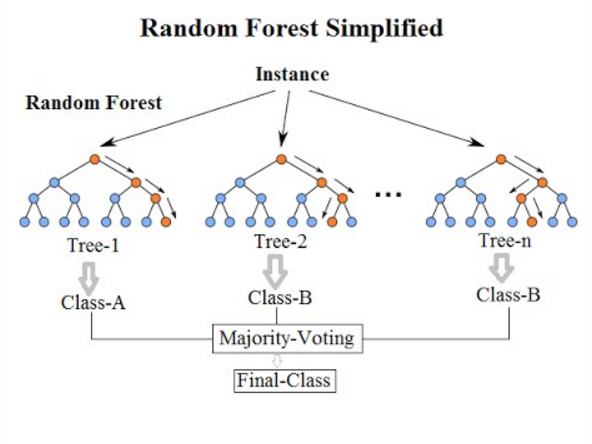

In [26]:
display(Image(url_images+'Random_forest_diagram_complete.png'))

Plotting decision boundary on train and test set...


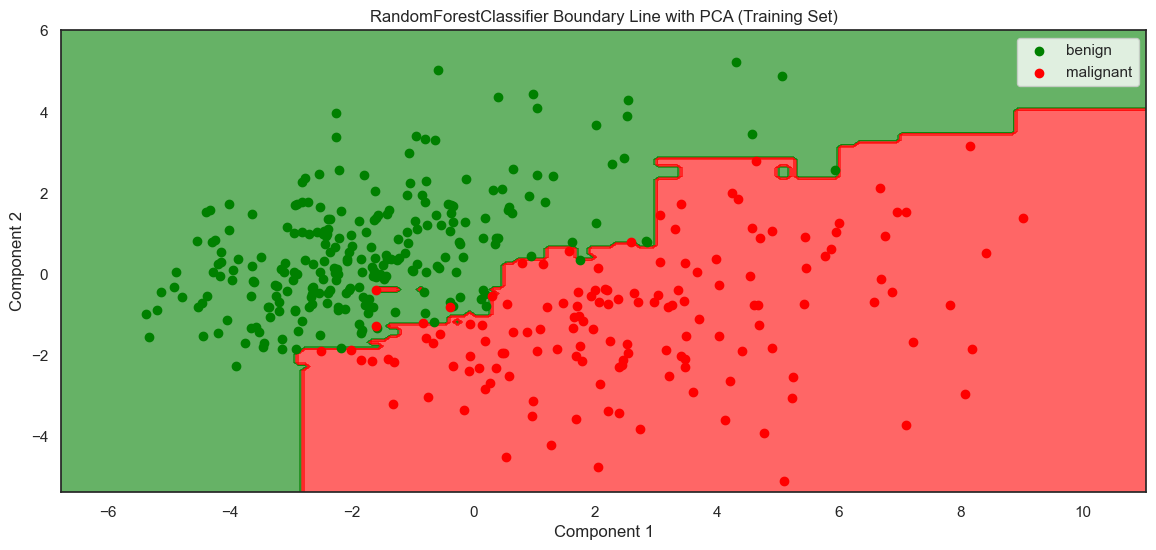

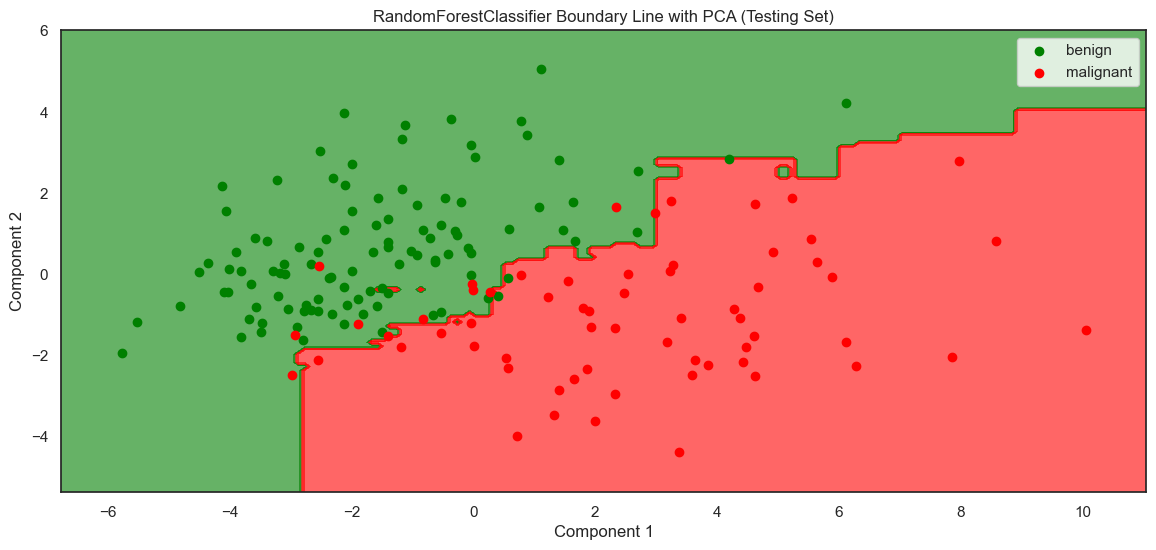

==================== Testing DECISION TREE Results ====================
              precision    recall  f1-score   support

           0       0.89      0.96      0.93       106
           1       0.93      0.81      0.86        62

    accuracy                           0.90       168
   macro avg       0.91      0.88      0.89       168
weighted avg       0.91      0.90      0.90       168

==================== Testing RANDOM FOREST Results ====================
              precision    recall  f1-score   support

           0       0.92      0.98      0.95       106
           1       0.96      0.85      0.91        62

    accuracy                           0.93       168
   macro avg       0.94      0.92      0.93       168
weighted avg       0.94      0.93      0.93       168



In [38]:
from sklearn.ensemble import RandomForestClassifier

# 1. instantiate model Random Forest with 50 decision trees
model = RandomForestClassifier(n_estimators=50,random_state=42) 
# 2. fit model to data
model.fit(X_train, y_train)   
# 3. predict on new data
y_pred = model.predict(X_test)    

# # drawing decision boundary  (only for teaching)
draw_boundary(RandomForestClassifier(n_estimators=50,random_state=42) ,  X_train,X_test,y_train.target,y_test.target)

# 4. Evaluation (Comparison with decision tree model)
print('='*20,'Testing DECISION TREE Results','='*20)
print(report_testing_dtree)

print('='*20,'Testing RANDOM FOREST Results','='*20)
print(classification_report(y_test, y_pred))
print('='*60)

**In Random Forest, multiple overfitting estimators can be combined to reduce the overfitting effect and find a better classification**

<div class="alert alert-block alert-warning" style='color:black'>
<b>NOTE:</b>
Since our model does not have huge data set, testing set is left with few observations to lead any real conclusion.
    </div>
    
<!--  <div class="alert alert-block alert-info" style='color:black'> -->

<!-- One disadvantage of using a holdout set for model validation is that we have lost a portion of our data to the model training. In the previous case, the 30% of the dataset does not contribute to the training of the model! This is not optimal, and can cause problems especially if the initial set of training data is small. -->
One way to address this is to use <a href="https://en.wikipedia.org/wiki/Cross-validation_(statistics)" >Cross-Validation</a>
<!-- </div> -->

In [39]:
model.feature_importances_

array([0.02002348, 0.12783746, 0.01951354, 0.01515692, 0.0886672 ,
       0.15901615, 0.00394647, 0.00816844, 0.00622083, 0.0569064 ,
       0.00748853, 0.0133286 , 0.02326078, 0.0151112 , 0.003833  ,
       0.0107898 , 0.0248897 , 0.01206664, 0.01956348, 0.1030638 ,
       0.2394688 , 0.01231347, 0.00936533])

## Cross validation
**Cross-validation** 
- I method using different portions of the data to iteratively train and test a model, and collect cumulative results. 
- It combines (averages) measures of performance in prediction on different iterations to obtain a better estimation of the prediction performance (quality) of a model.
- It might be convenient, e.g., to understand whether the selected class of model might work well on the data

The __K-fold Cross-Validation__ scheme randomly divides the set of observations into k equal sized subsamples:
- k − 1 subsamples are used as training data
- 1 subsample is used as test data
- The process is then repeated k times with each of the k subsamples used exactly once as testing data.
- The k results can then be averaged to produce a single estimation to give an estimate of the model's predictive performance.
- Of course, the subsamples shall be split using _stratified_

Visually, it might look something like this:

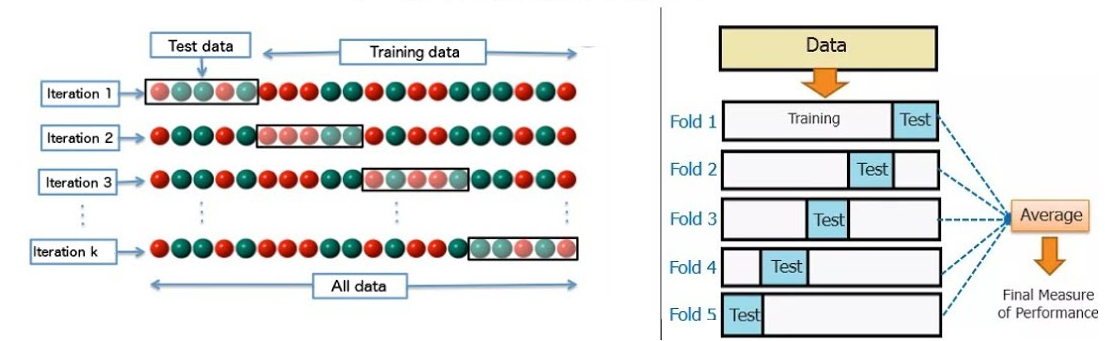

In [28]:
display(Image(url_images+'K-fold_cross_validation.png'))

 <div class="alert alert-block alert-info" style='color:black'>
<b>Tip</b>
When you have a small dataset, it is recommended to use cross-validation to estimate the global predictive power of a learning algorithm. 

</div>


We will use [*StratifiedKFold()*](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html?highlight=stratifiedkfold#sklearn.model_selection.StratifiedKFold) which is a variation of k-fold which returns stratified folds. 

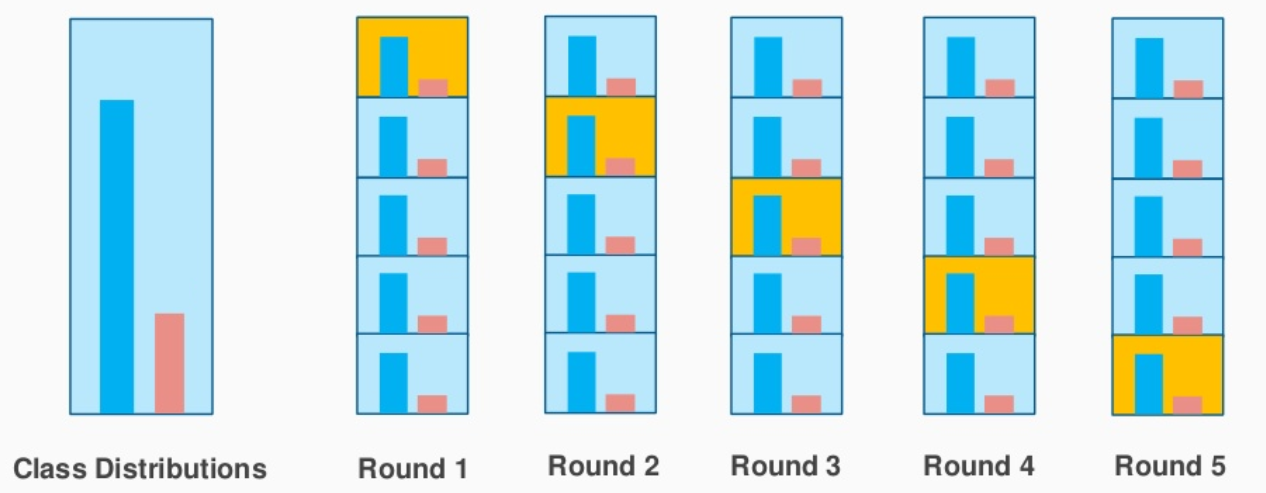

In [29]:
display(Image(url_images+'stratifiedKFold_2.png'))

What happens under the hood? How is this done?
- `__Alert: here we write explicitly all steps of cross-validation__`
- Of course, there is a more compact you shall use... 
   - we show it later

In [31]:
from sklearn.model_selection import StratifiedKFold
import sklearn.metrics as metrics

def cv_scores_explained(model, X, y):
    # Stratified 5 folds 
    cv = StratifiedKFold(n_splits=5)
    
    # Lists to store scores by folds 
    recalls_train, recalls_test, f1_test, acc_test = list(), list(), list(), list()
    
    # for each round fitting model on K-1 folds and test it on 1 fold        
    for train_index, test_index in cv.split(X, y): # split() generate indices to split data into training and test set.
        
        ## 1. getting data for each round ##
        X_train = X[train_index, :]  # features data for fitting model        
        X_test  = X[test_index, :]   # features data for testing model
        y_train = y[train_index]     # target vector for fitting model    
        y_test  = y[test_index]      # target vector for testing model
        
               
        ## 2. data scaling ##  
        scaler = StandardScaler()
        # fitting and scaling a StandardScaler
        X_train = scaler.fit_transform(X_train) # learn the parameters and scaling  
        # scaling on test set
        X_test = scaler.transform(X_test) # scaling using training parameters
        
        ## 3. fit model on training set ##
        model.fit(X_train, y_train)
        
        ## 4. prediciton on test set ##
        y_pred = model.predict(X_test)
        
        ## 5. evalution model ##
        # getting testing accuracy, f1 and recall score 
        acc = metrics.accuracy_score(y_test, y_pred)
        f1 = metrics.f1_score(y_test, y_pred)
        recall = metrics.recall_score(y_test, y_pred)        
        # getting training recall score 
        y_train_pred = model.predict(X_train)
        recall_training = metrics.recall_score(y_train, y_train_pred)
        
        ## 6. saving partial 'fold' results ##
        recalls_test.append(recall)
        acc_test.append(acc)
        f1_test.append(f1)
        recalls_train.append(recall_training)
        
    return pd.DataFrame({'train_recall':recalls_train, 'test_recall':recalls_test,'test_f1':f1_test,'test_accuracy':acc_test}) 

In [32]:
X = df_X.values  # Features matrix
y = df_y.values # target array
estimator = DecisionTreeClassifier(random_state=42)
cv_scores_explained(estimator,X,y).mean()

train_recall     1.000000
test_recall      0.902439
test_f1          0.898455
test_accuracy    0.924550
dtype: float64

In [34]:
X = df_X.values  # Features matrix
y = df_y.values # target array
estimator = DecisionTreeClassifier(random_state=41)#42
cv_scores_explained(estimator,X,y).mean()

train_recall     1.000000
test_recall      0.907317
test_f1          0.903151
test_accuracy    0.928185
dtype: float64

__Here is the more compact (and actually used) way to perform cross-validation:__
- This is based on the [cross_validate](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html) function:
  * allows specifying multiple metrics for evaluation.
  * returns a dict containing fit-times, score-times (and optionally training scores as well as fitted estimators) in addition to the test score.

In [35]:
from sklearn.model_selection import cross_validate
# A Pipeline makes it easier to get composed estimators
#   This is useful, e.g., to automate some steps under cross-validation:
#.  This is typically used to combine transformers with classifiers/regressors
#   Here, We use it to 'combine' the model with a StandardScaling (for each iteration, it automatically scales fit_and_scales the train set (and scales the test set))
from sklearn.pipeline import make_pipeline
    
def cv_scores(model, xvalues, yvalues):
    """
    Evaluate metric(s) by cross-validation 
    Return CV scores and scores of the model for each run of the cross validation.
    """
    
    # for the complete metrics:  https://scikit-learn.org/stable/modules/model_evaluation.html
    scoring=('recall','precision','accuracy', 'f1') # accuracy,recall, precision, f1 on positive class 
    
    # Also in cross-validation, data transformations should be learned from a training set and applied to held-out data for prediction 
    clf = make_pipeline(StandardScaler(), model)
    
    # cross_validate uses Stratified 5 folds (80%-20% splitting data) https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html
    cv_results = cross_validate(clf, xvalues, yvalues, cv=5, return_train_score=True, scoring=scoring)
    
    # Folds scores
    df_folds = pd.DataFrame(cv_results)        
    df_cv_scores = df_folds[sorted(cv_results.keys())].mean() # CV scores
    df_cv_scores['model'] = type(model).__name__
    
    return  df_cv_scores, df_folds



In [36]:
X = df_X.values  # Features matrix
y = df_y.values # target array
estimator = DecisionTreeClassifier(random_state=42)
df_dtree_cv, df_folds = cv_scores(estimator,X,y)
# df_dtree_cv
df_folds.mean()

fit_time           0.004178
score_time         0.002622
test_recall        0.902439
train_recall       1.000000
test_precision     0.897134
train_precision    1.000000
test_accuracy      0.924550
train_accuracy     1.000000
test_f1            0.898455
train_f1           1.000000
dtype: float64

Decision tree model is an over fit. There are big differences between training scores and testing scores.

In [37]:
estimator = RandomForestClassifier(n_estimators=50,random_state=42)
df_rf_cv, _  = cv_scores(estimator,X,y)
df_rf_cv

fit_time                         0.032246
score_time                       0.002839
test_accuracy                    0.958736
test_f1                          0.941984
test_precision                   0.975238
test_recall                      0.912195
train_accuracy                        1.0
train_f1                              1.0
train_precision                       1.0
train_recall                          1.0
model              RandomForestClassifier
dtype: object

In [40]:
# Test scores comparison
df_cv_scores = pd.DataFrame([df_dtree_cv,df_rf_cv])
#df_cv_scores[['model','test_accuracy','test_f1','test_precision','test_recall']].style.background_gradient(cmap='Blues')
df_cv_scores[['model','test_accuracy','test_f1','test_precision','test_recall']].style.background_gradient(cmap='Blues')

,model,test_accuracy,test_f1,test_precision,test_recall
0,DecisionTreeClassifier,0.924550,0.898455,0.897134,0.902439
1,RandomForestClassifier,0.958736,0.941984,0.975238,0.912195


Random Forest Classifier 
- mitigates the overfitting problem reducing the difference between training and testing scores, 
- but we can do better...

Let's Go pimp our model!

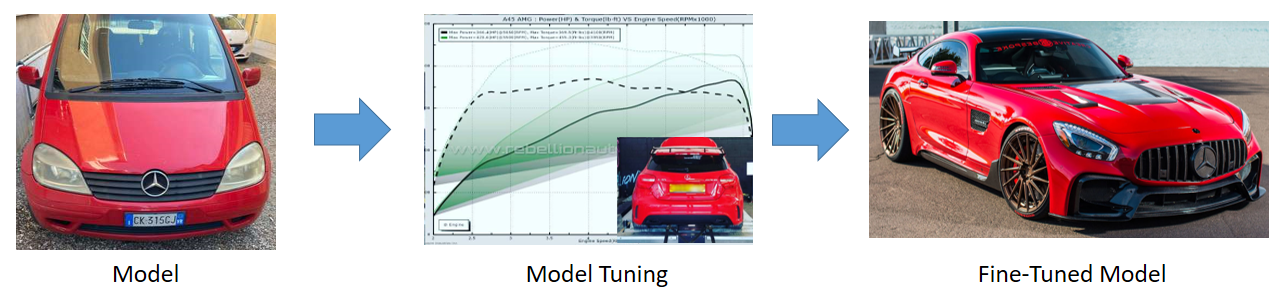

In [41]:
display(Image(url_images+'model_tuning.png'))

# Model Tuning 


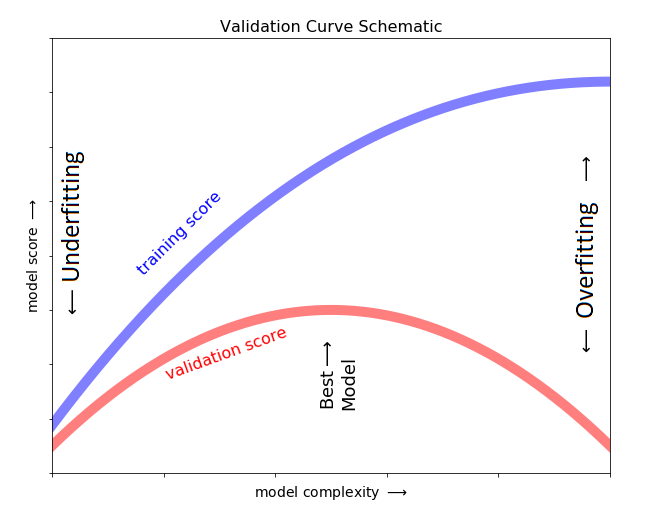Overfitting is caused by making a model more complex than necessary.

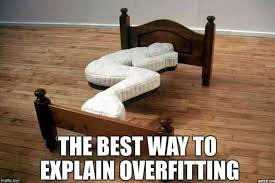

In [42]:
display(Image(url_images+'overfitting.jpg'))

The Model's ability to generalize to new data is based on factors such as:
- the complexity of the model
- the model's performance on training data respect on test set

We must find the trade-off between fitting our data well, but also fitting the data as simply as possible. 

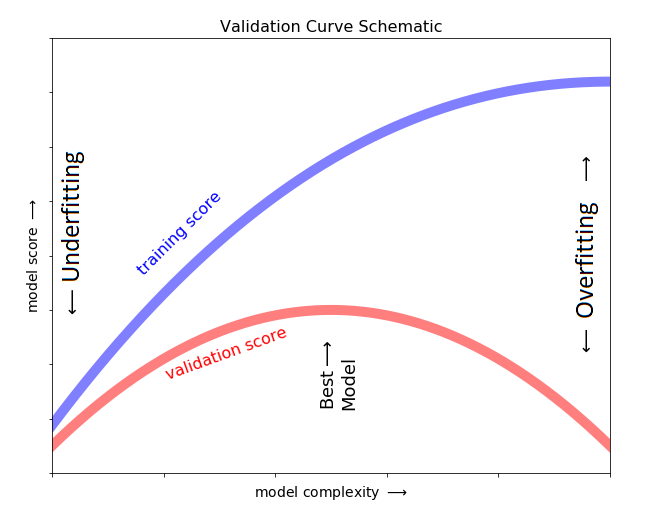

In [43]:
display(Image(url_images+'validation.png'))

<!-- In first article of Stephanie and Tony on R2D3, we created a model that distinguishes homes in San Francisco from those in New York. In the [second article](http://www.r2d3.us/visual-intro-to-machine-learning-part-2/), they will talk about tuning and the Bias-Variance tradeoff. -->

In the previous section, we saw the basic recipe for applying a supervised machine learning model. 

Now we can complete the recipe by adding _Hyperparameters tuning_ to deal with the overfitting problem:
1. Choose a model class
2. **Choose best model hyperparameters**
3. Fit the model to the training data
4. Use the model to predict labels for new data

In machine learning, a **hyperparameter is a parameter whose value is used to control the learning process and complexity of the model**. 
- It is fixed by the modeler
- It is not changed during training

<!-- The choice of model and choice of hyperparameters are the most important part of using these tools and techniques effectively. -->
In order to make an informed choice, we need a way to validate that our model and our hyperparameters are a good fit to the data.
- To do this, **we need to retain some subset of training data (validation set) to evaluate the performance of the model to changes in its hyperparameters.**
  - We now split in 3!
  - Training data, validation data, test data
  
<!-- ![](img/splitting_validation.png) -->

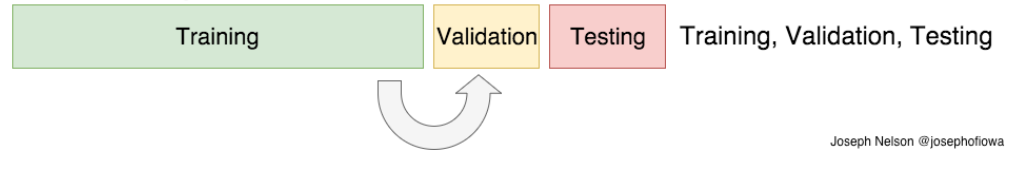

In [44]:
display(Image(url_images+'splitting_validation.png'))

As we have seen before, one disadvantage of using a holdout set for model validation is that 
- We lose a portion of our data. It cannot be used for training. 

This is not optimal, and can cause problems especially if the data data is small.  
- To overcome this, we perform a 5-fold cross validation to validate the results

<!-- ![](notebook/img/splitting_2.png) -->


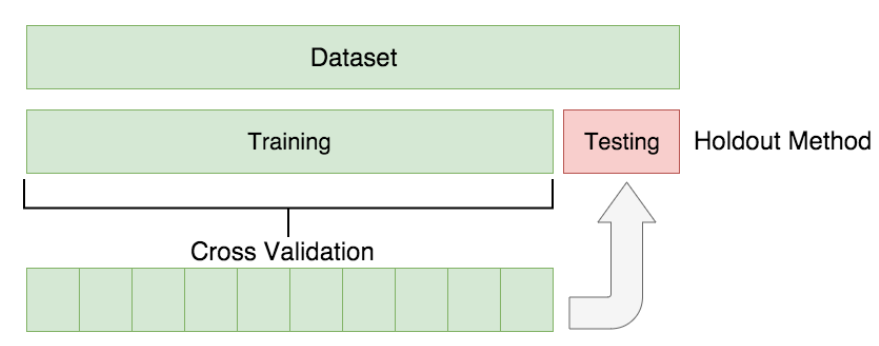

In [45]:
display(Image(url_images+'splitting_2.png'))

<!-- **Why do we need a validation set?**

Learning the parameters of a prediction function and testing it on the same data is a methodological mistake: a model that would just repeat the labels of the samples that it has just seen would have a perfect score but would fail to predict anything useful on yet-unseen data. This situation is called overfitting. 


 -->

## Validation Curve

**[Decision-tree learners](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) can create over-complex trees that do not generalise the data well**. 
- This is called overfitting. 

Mechanisms such as the following can mitigate this problem:
- pruning, 
- setting the minimum number of samples required at a leaf node or 
- setting the maximum depth of the tree 

[Pruning](https://en.wikipedia.org/wiki/Decision_tree_pruning) reduces the complexity of the classifier, and hence improves predictive accuracy by reducing overfitting.

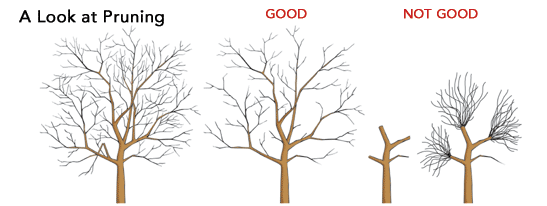

In [46]:
display(Image(url_images+'pruning.png'))

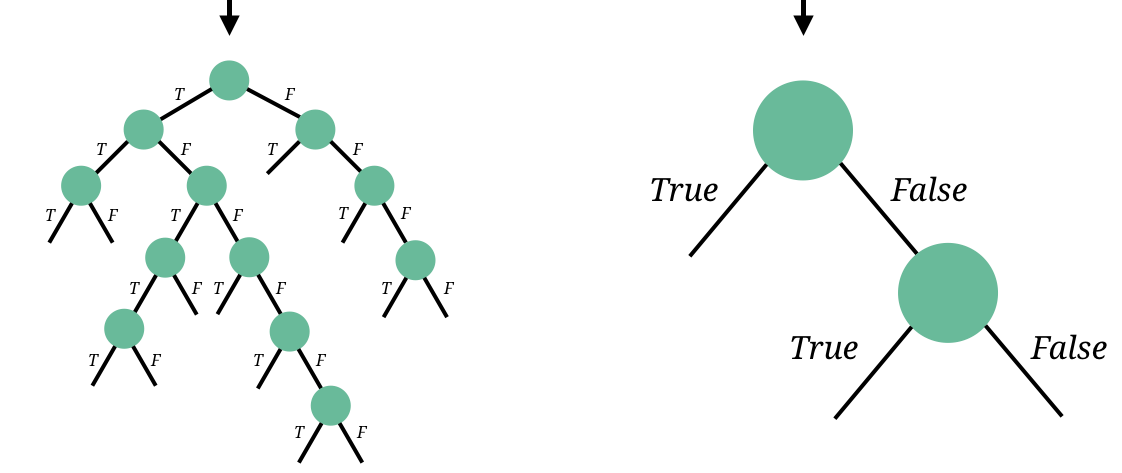

In [47]:
display(Image(url_images+'cp.png'))

<!-- --Bias is the difference between the Predicted Value and the Expected Value
--The Variance is when the model takes into account the fluctuations in the data i.e. the noise as well. -->

We can use the [*min_samples_leaf*](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) tunable parameter to tune the decision tree model complexity 

We can use [sklearn.model_selection.validation_curve](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.validation_curve.html#sklearn.model_selection.validation_curve) to plot
- the influence of a single hyperparameter on the training score and 
- the validation score in order to find out whether the estimator is overfitting or underfitting for some hyperparameter values.



Saving tree in file plot_tree_validation.pdf


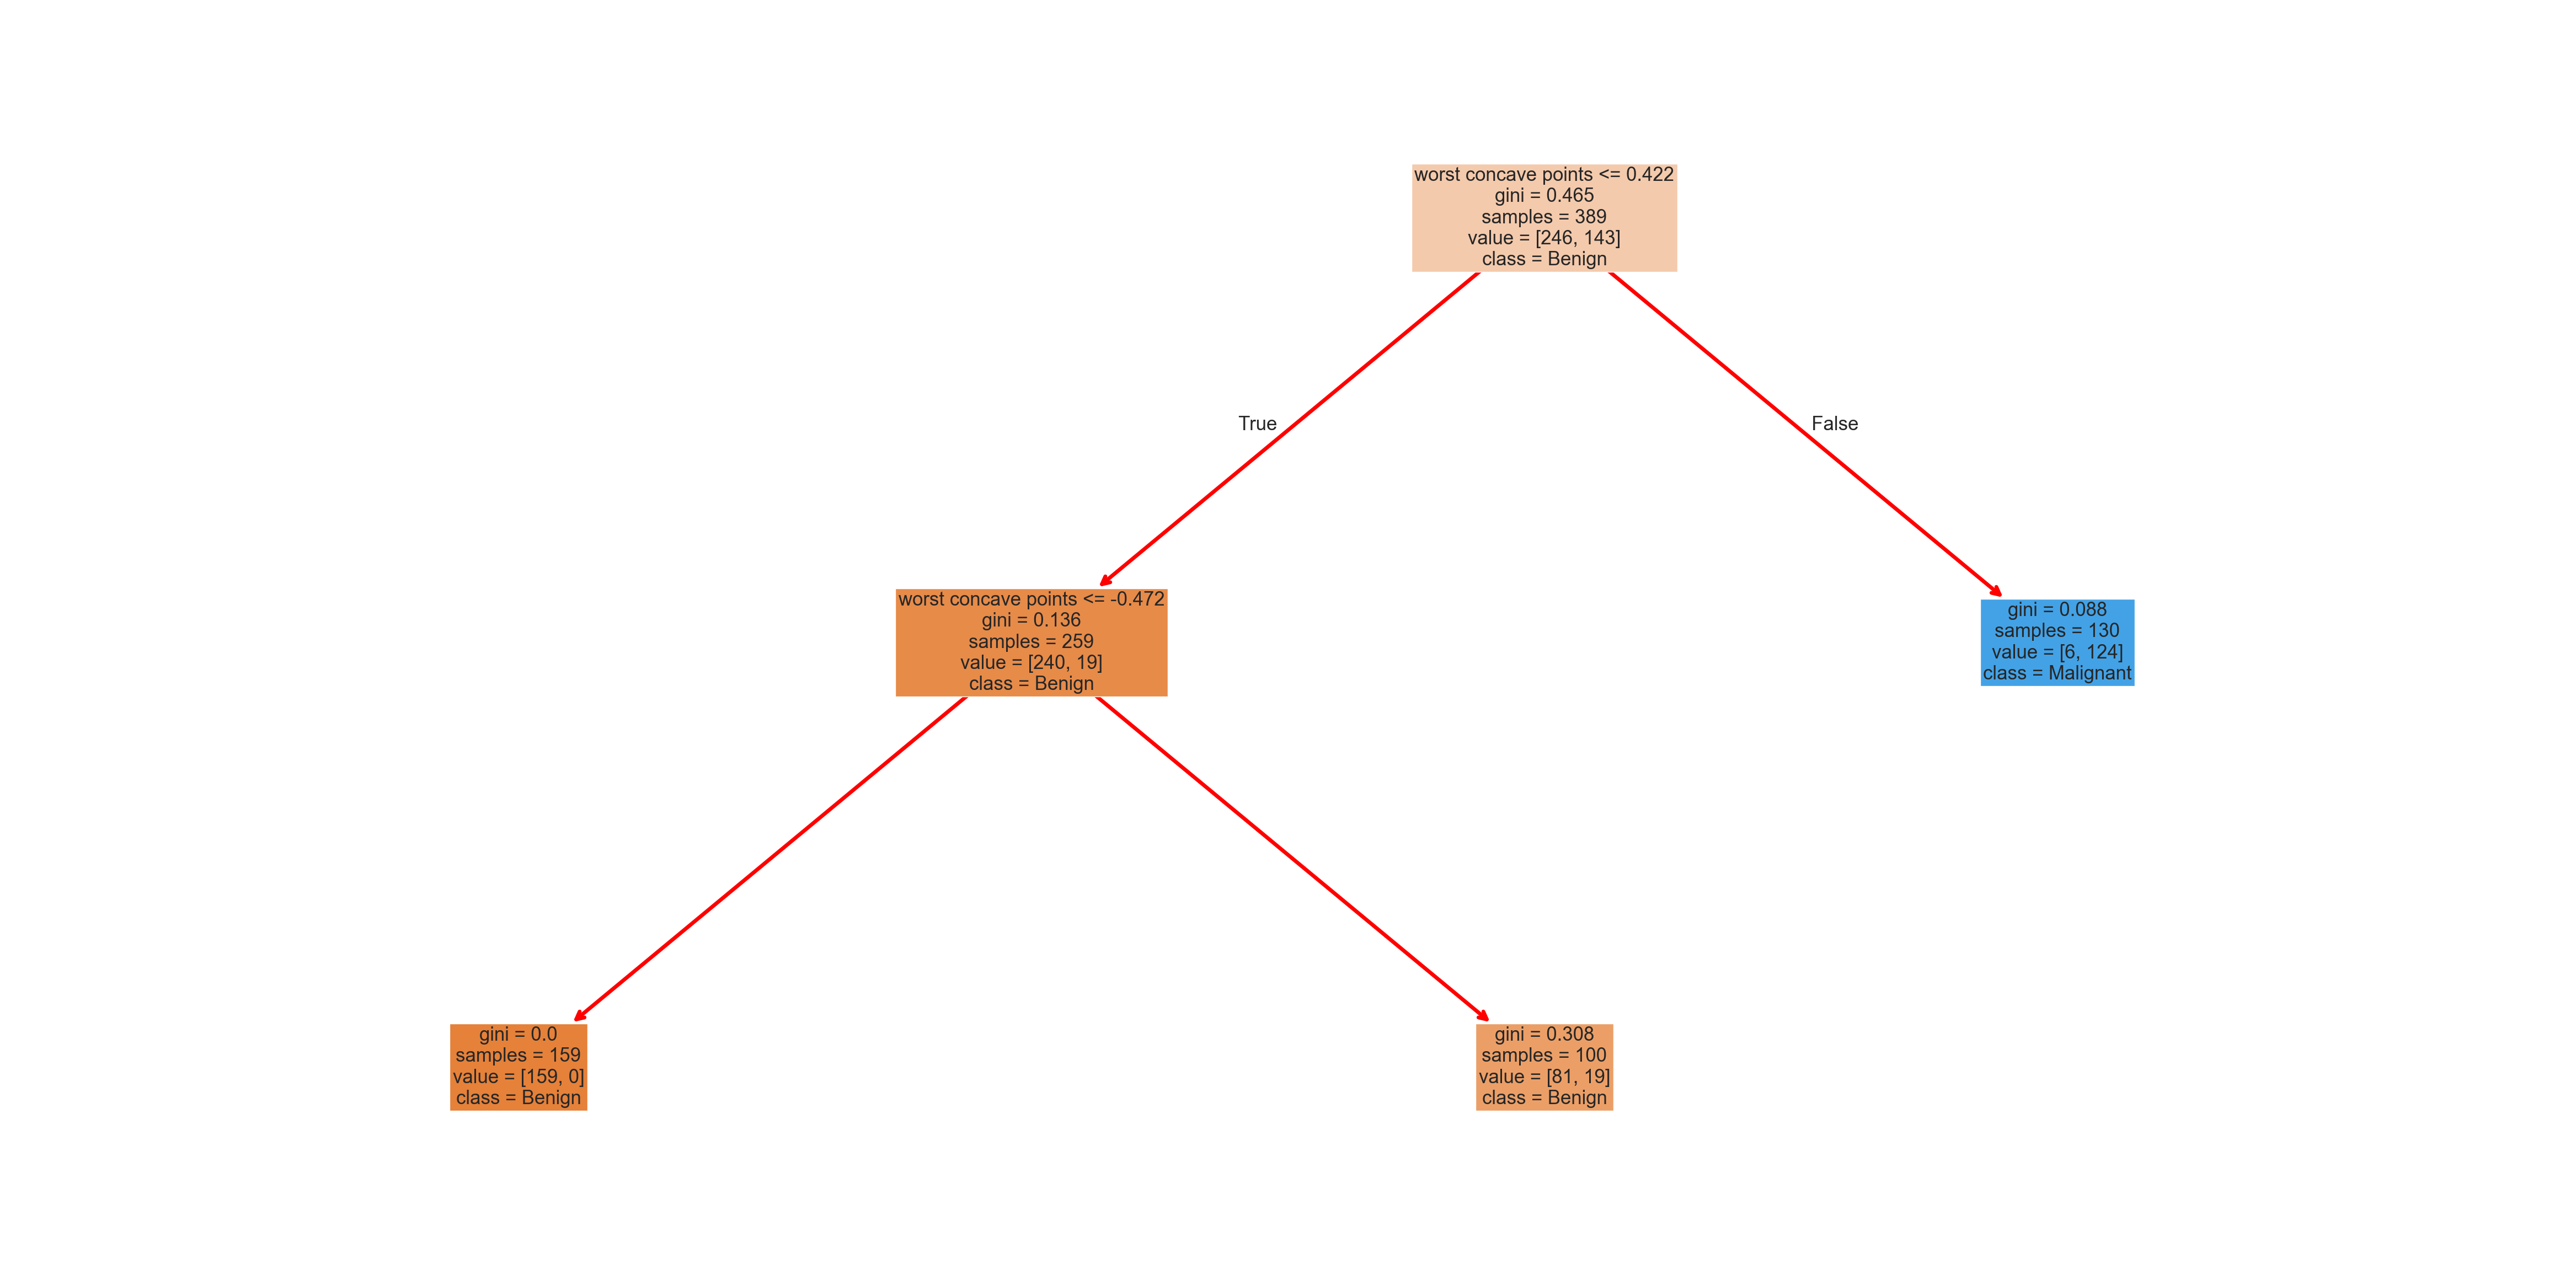

In [48]:
from pdai_utils import plot_decision_tree
dt = DecisionTreeClassifier(random_state = 42, min_samples_leaf=100)
dt.fit(X_train,y_train)
plot_decision_tree(dt , X_train,y_train, df_X.columns,file_name='plot_tree_validation.pdf')
# evalutation
# test_score = metrics.recall_score(y_test, dt.predict(X_test))
# train_score = metrics.recall_score(y_train, dt.predict(X_train))
# print(f'Train score {train_score:.2f}, Test score {test_score:.2f}')

[1, 5, 9, 13, 17, 21, 25, 29, 33]


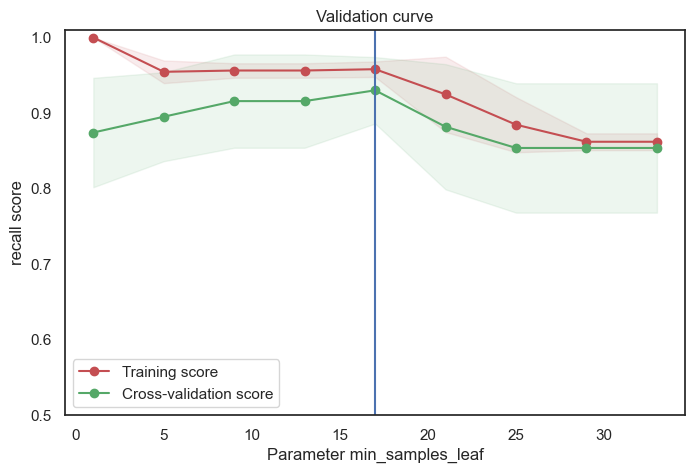

In [49]:
from pdai_utils import validation_curve_model
dtree =  DecisionTreeClassifier(random_state = 42)

param_range = range(1,34,4) 
print(list(param_range))
param_name="min_samples_leaf"
ylim=[0.50, 1.01]


sns.set(style="white")
validation_curve_model(X_train,y_train, dtree, param_name, param_range, cv=5, ylim=ylim )

plt.show()

The chart above  is validation curve, and we see the following essential features:
* The training score is everywhere higher than the validation score. This is generally the case: the model will be a better fit to data it has seen than to data it has not seen.
* **For very high model complexity (a high-variance model, min_samples_leaf value from 1 to 13), the training data is overfit**, which means that the model predicts the training data very well, but fails for any previously unseen data.
* **For very low model complexity (a high-bias model, min_samples_leaf value after 20), the training data is underfit**, which means that the model is a poor predictor both for the training data and for any previously unseen data.
* For some intermediate value, **the validation curve has a maximum. This level of complexity indicates a suitable trade-off between bias and variance is 17**

## Grid Search
In practice, models generally have more than one knob to turn. 
- Thus, plots of validation curves change from lines to multidimensional surfaces. 

Grid Search tries all the possible combinations of parameter values (knobs to turn) which are evaluated using crossvalidation and the best combination is retained.

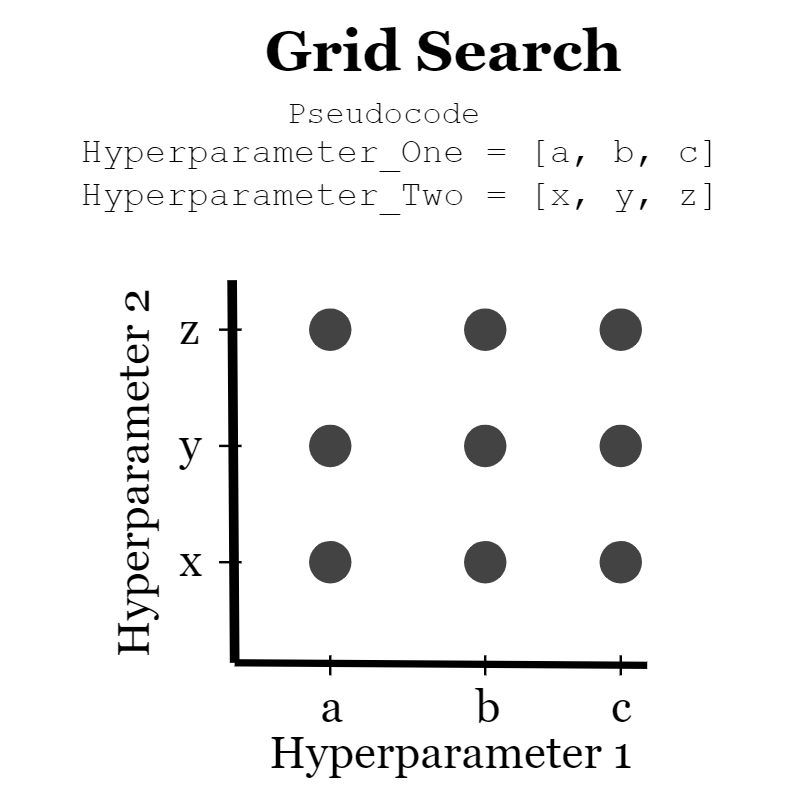

In [50]:
display(Image(url_images+'grid_search.png'))

In [51]:

print({"min_samples_leaf": list(range(1,30,2)), # len = 15
        "min_samples_split":list(range(2,8,1)), # len = 6
        "max_depth": list(range(1,20,2)) # len = 10
       })
# all possibile combinations = 15 * 10 * 6 = 900 

{'min_samples_leaf': [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29], 'min_samples_split': [2, 3, 4, 5, 6, 7], 'max_depth': [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]}


[*sklearn.model_selection.GridSearchCV*](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html): Exhaustive search over specified parameter values for an estimator.

In [52]:
dtree =  DecisionTreeClassifier(random_state = 42)

parameters_grid={"min_samples_leaf": range(1,30,2),
                 "min_samples_split":range(2,8,1),
                 "max_depth": range(1,20,2)
               }
 
from sklearn.model_selection import GridSearchCV
#(Stratified)5Fold,
clf = GridSearchCV(dtree, parameters_grid, scoring='recall',n_jobs=4, verbose=2)
clf.fit(X_train,y_train)

Fitting 5 folds for each of 900 candidates, totalling 4500 fits
[CV] END max_depth=1, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END max_depth=1, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END max_depth=1, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END max_depth=1, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END max_depth=1, min_samples_leaf=1, min_samples_split=2; total time=   0.0s
[CV] END max_depth=1, min_samples_leaf=1, min_samples_split=3; total time=   0.0s
[CV] END max_depth=1, min_samples_leaf=1, min_samples_split=3; total time=   0.0s
[CV] END max_depth=1, min_samples_leaf=1, min_samples_split=3; total time=   0.0s
[CV] END max_depth=1, min_samples_leaf=1, min_samples_split=3; total time=   0.0s
[CV] END max_depth=1, min_samples_leaf=1, min_samples_split=4; total time=   0.0s
[CV] END max_depth=1, min_samples_leaf=1, min_samples_split=3; total time=   0.0s
[CV] END max_depth=1, min_samples_

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': range(1, 20, 2), 'min_samples_leaf': range(1, 30, 2), 'min_samples_split': range(2, 8)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is di

In [53]:
print('Recall score ', clf.best_score_, ' with ', clf.best_params_)


Recall score  0.9300492610837438  with  {'max_depth': 3, 'min_samples_leaf': 17, 'min_samples_split': 2}


In [54]:
dt = DecisionTreeClassifier(random_state=42, max_depth=3, min_samples_leaf=17, min_samples_split=2)
dt.fit(X_train,y_train)
#plot_decision_tree(dt , X_train,y_train, df_X.columns)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",17
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current n

In [55]:
# Evalution on Test Set
dtree = DecisionTreeClassifier(random_state=42, max_depth=3, min_samples_leaf=17, min_samples_split=2)
dtree.fit(X_train, y_train)    
print('='*20,'Testing Fine-Tuned DecisionTree Results','='*20)
print(classification_report(y_test, dtree.predict(X_test) ))

# Evalution using Cross Validation
print('='*20,'Cross Validation Fine-Tuned DecisionTree ','='*20)
df_tuned_dtree_cv, _ = cv_scores(dtree,X,y)
df_tuned_dtree_cv['model'] = 'Fine-Tuned DecisionTree'
df_tuned_dtree_cv

==================== Testing Fine-Tuned DecisionTree Results ====================
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       106
           1       0.89      0.89      0.89        62

    accuracy                           0.92       168
   macro avg       0.91      0.91      0.91       168
weighted avg       0.92      0.92      0.92       168

==================== Cross Validation Fine-Tuned DecisionTree  ====================


fit_time                          0.002712
score_time                        0.002649
test_accuracy                     0.928282
test_f1                           0.903824
test_precision                    0.896725
test_recall                       0.912195
train_accuracy                    0.944795
train_f1                          0.925292
train_precision                   0.921372
train_recall                      0.930488
model              Fine-Tuned DecisionTree
dtype: object

### Random Forest


In [ ]:
rf =  RandomForestClassifier(random_state = 42)

parameters_grid={"min_samples_leaf": range(1,10,2),
                 "min_samples_split":range(2,6,1),
                 "max_depth": range(1,10,2),
                 "n_estimators": range(20,101,20)
               }
 
from sklearn.model_selection import GridSearchCV
clf = GridSearchCV(rf, parameters_grid,scoring='recall',n_jobs=4,verbose=2)
clf.fit(X_train,y_train)

In [ ]:
print('Recall score ', clf.best_score_, ' with ', clf.best_params_)

In [ ]:
X = df_X.values  # Features matrix
y = df_y.values 

# Evalution on Test Set
model = RandomForestClassifier(random_state=42, max_depth=5, min_samples_leaf=1, min_samples_split=2,n_estimators=20) 
model.fit(X_train, y_train)    
print('='*20,'Testing Fine-Tuned RandomForest Results','='*20)
print(classification_report(y_test, model.predict(X_test) ))

# Cross Validation
print('='*20,'Cross Validation Fine-Tuned RandomForest ','='*20)
df_tuned_rf_cv, _ = cv_scores(model,X,y)
df_tuned_rf_cv['model'] = 'Fine-Tuned RandomForest'
df_tuned_rf_cv

In [ ]:
df_cv_scores = pd.DataFrame([df_dtree_cv,df_tuned_dtree_cv, df_rf_cv,df_tuned_rf_cv]).sort_values('test_recall', ascending=False)
df_cv_scores[['model','test_accuracy','test_f1','test_precision','test_recall',]].style.background_gradient(cmap='Blues')

Fine-Tuned RandomForest models has 92.2% recall

## Save and Load Models
Pickle is the standard way of serializing objects in Python.

In [ ]:
import pickle
model_path = 'data'
# save models
pickle.dump(scaler, open(f"{model_path}/scaler", 'wb'))
pickle.dump(model, open(f"{model_path}/best_trained_model", 'wb')) 

# load models
loaded_scaler = pickle.load(open(f"{model_path}/scaler", 'rb')) 
loaded_model = pickle.load(open(f"{model_path}/best_trained_model", 'rb')) 



In [ ]:
sampleX = df_X.sample(2)
make_pipeline(loaded_scaler,loaded_model).predict(sampleX) # Apply transforms to the data, and predict with the final estimator
# loaded_model.predict(loaded_scaler.transform(sampleX))

## Machine Learning Pipeline (or your should-be-project-outline :D)
Below is a flowchart of typical workflow in model training. The best parameters can be determined by grid search techniques.

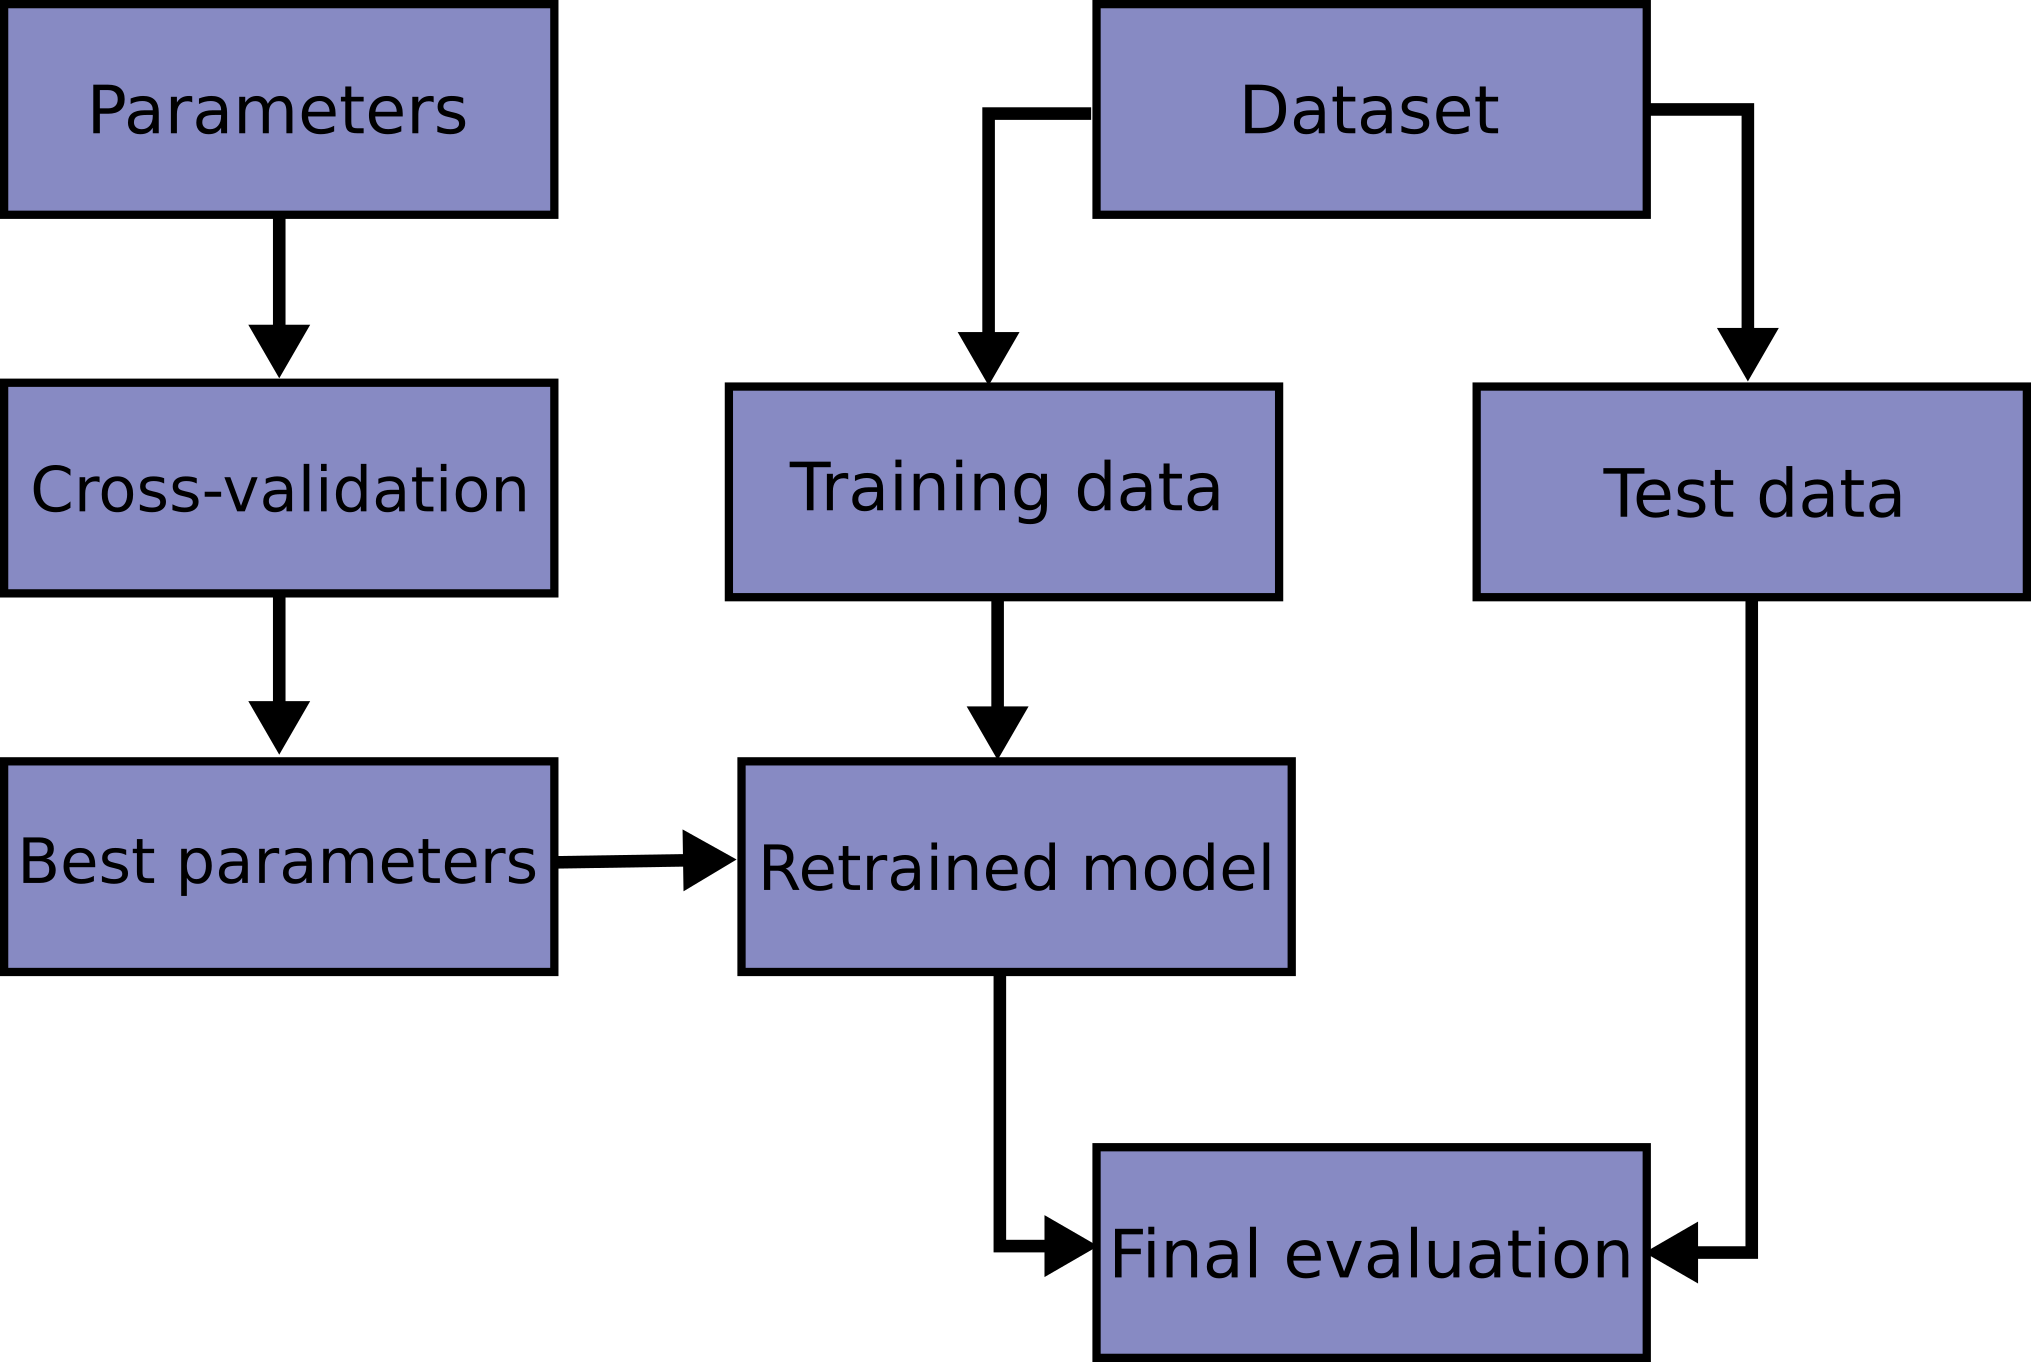

In [56]:
display(Image(url_images+'grid_search_workflow.png', width=700))

In [57]:
import numpy as np
from sklearn.datasets import load_breast_cancer # to load the dataset
from sklearn.preprocessing import StandardScaler #for Scaling the features
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from IPython.display import display, Markdown 
import pickle

class MLPipeline():
    
    def __init__(self,model,test_size=0.3,k_folds=5):
        self.model = model
        self.model_name = type(model).__name__
        self.test_size = test_size
        self.k_folds = k_folds
        self.scaler = None

    def load_data(self):
        #load dataset 
        self.X,self.y = load_breast_cancer(return_X_y=True)         


    def split_data(self):
        # Splitting train and test data 
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(self.X,self.y, test_size=self.test_size, stratify=self.y, random_state=1)
        
    def preprocessing(self):
        # Scaling features
        self.scaler = StandardScaler()
        self.X_train =self.scaler.fit_transform(self.X_train)              
        self.X_test =self.scaler.transform(self.X_test) 
        
    def parameter_tuning(self, parameters):
        # GridSearchCV to find optimal parameters
        grid = GridSearchCV(self.model, parameters, cv=self.k_folds)
        grid.fit(self.X_train, self.y_train)

        # Getting optimal parameters
        self.best_score = grid.best_score_   
        self.best_params= grid.best_params_
        self.best_model = grid.best_estimator_        
        

    def model_evaluation(self):
        # Getting train and test accuracy        
        self.best_model.fit(self.X_train, self.y_train)
        self.train_accuracy = self.best_model.score(self.X_train, self.y_train)
        self.test_accuracy = self.best_model.score(self.X_test, self.y_test)
        
    def k_fold_cross_validation(self):
        # Model definition
        if self.scaler:
            pipeline = make_pipeline(StandardScaler(),self.best_model)
        else:
            pipeline = self.best_model
        # Applying k-fold and getting scores
        self.kfold_scores = cross_val_score(pipeline, self.X, self.y, cv=self.k_folds)
        
    def save_model(self,model_path):
        # Save optimum model and Scaler
        if self.scaler:
            pickle.dump(self.scaler,  open(f"{model_path}/StandardScaler", 'wb'))
        pickle.dump(self.tree, open(f"{model_path}/best_model", 'wb'))        

    def markdown_report(self):
        display(Markdown(
        f"""---
        \n Model: {self.model_name}
        \nDataset size {len(self.X)}, Test size {self.test_size*100:.1f}% 
        \n*Optimal parameters (GridSearchCV {self.k_folds}-Folds ):*
        \n   - Best params **{self.best_params}**
        \n   - Accuracy **{self.best_score:.2f}** 
        \n*Model_evaluation (test size {self.test_size*100:.1f}%):*
        \n   -  Train accuracy **{self.train_accuracy:.2f}**
        \n - Test accuracy **{self.test_accuracy:.2f}**
        \n*Cross Validation Score :*
        \n   - Avarage Accuracy **{np.mean(self.kfold_scores):.2f}**   +/-{np.std(self.kfold_scores):.2f} \n---""" ))
   

 
    

In [58]:
model = DecisionTreeClassifier(random_state=1)
parameters_grid = {'criterion': ['gini','entropy'], 'splitter': ['best','random'], 'max_depth': [2,3,4]}

pipeline = MLPipeline(model=model)
pipeline.load_data()
pipeline.split_data()
pipeline.preprocessing()
pipeline.parameter_tuning(parameters_grid)
pipeline.model_evaluation()
pipeline.k_fold_cross_validation()
# pipeline.save_model('data')
pipeline.markdown_report()

---
        
 Model: DecisionTreeClassifier
        
Dataset size 569, Test size 30.0% 
        
*Optimal parameters (GridSearchCV 5-Folds ):*
        
   - Best params **{'criterion': 'entropy', 'max_depth': 3, 'splitter': 'best'}**
        
   - Accuracy **0.95** 
        
*Model_evaluation (test size 30.0%):*
        
   -  Train accuracy **0.97**
        
 - Test accuracy **0.95**
        
*Cross Validation Score :*
        
   - Avarage Accuracy **0.93**   +/-0.02 
---

<div class="alert alert-block alert-warning" style='color:black'>
    <b>NOTE:</b>
In an ideal world, you should have an independent test set to verify the performance of your model. 
Sometimes it happens that our dataset is not large enough to be divided into training, validation, and testing sets, so people use cross-validation to use as much data as possible for both, training and testing.</div>

# Next Lesson
__Please follow the instructions in the *Setup-your-machine* page of our wiki!__**
- To install the __KNIME__ Analytics Platform



# APPENDIX




## Handling Imbalanced Datasets
Imbalanced datasets are those where there is a severe skew in the class distribution. This bias in the training dataset can influence many machine learning algorithms, leading some to ignore the minority class entirely. 

There are two major groups of selection algorithms:

- the under-sampling method by randomly selecting a given number of samples from the majority class.
- the over-sampling methods by repeating some samples (or use some heuristic) and balance the number of samples between the dataset

Below, how to use sampling techniques implemented in the [imbalanced-learn Python library](https://imbalanced-learn.org/stable/) to deal with imbalanced datasets.

In [ ]:
!pip install imbalanced-learn 

In [ ]:
####pd.Series(y_train).value_counts()
y_train["target"].value_counts()
#y_train.value_counts()

In [ ]:
# under-sampling
from imblearn.under_sampling import RandomUnderSampler

sampler = RandomUnderSampler(random_state=0)
X_res_u, y_res_u = sampler.fit_resample(X_train, y_train)   
###pd.Series(y_res_u).value_counts()
y_res_u["target"].value_counts()
#y_res_u.value_counts()

In [ ]:
#  over-sampling
from imblearn.over_sampling import RandomOverSampler, SMOTE

sampler = RandomOverSampler(random_state=0)
X_res_os, y_res_os = sampler.fit_resample(X_train, y_train)   
###pd.Series(y_res_os).value_counts()
y_res_os["target"].value_counts()
#y_res_os.value_counts()

In [ ]:
#  over-sampling using a heuristic
#instead repeating the same samples when over-sampling, we can use some specific heuristic instead like SMOTE to create synthetic data
sampler = SMOTE(random_state=0) # Synthetic Minority Oversampling Technique https://arxiv.org/pdf/1106.1813.pdf
X_res_smote, y_res_smote = sampler.fit_resample(X_train, y_train)   
###pd.Series(y_res_smote).value_counts()
y_res_smote["target"].value_counts()
#y_res_smote.value_counts()

In [ ]:
imb_dataset = {'RandomUnderSampler':(X_res_u, y_res_u),
              'RandomOverSampler':(X_res_os, y_res_os),
               'SMOTE':(X_res_smote, y_res_smote)}
for n, d in imb_dataset.items():
    model.fit(d[0], d[1])  #fit model to data (training)
    y_pred = model.predict(X_test) #predict on new data 

    # evaluation
    print('='*10,f'Testing Set Results ({n})','='*10)
    print(classification_report(y_test, y_pred))
    print('='*60)

## Features importance   

The importance of a feature is computed as the (normalized) total
reduction of the criterion brought by that feature.
It is also known as the Gini importance.



Many model forms describe the underlying impact of features relative to each other. In scikit-learn, Decision Tree models and ensembles of trees such as Random Forest, Gradient Boosting, and Ada Boost provide a feature_importances_ attribute when fitted.

In [ ]:
model = DecisionTreeClassifier(random_state=42) 
# 2. fit model to data (training)
model.fit(X_train, y_train)   

pd.Series(dict(zip(df_X.columns,model.feature_importances_ ))).plot(kind='bar')
plt.show()

Warning: impurity-based feature importances can be misleading for high cardinality features (many unique values).  
    
:func:`sklearn.inspection.permutation_importance` as an alternative.

[sklearn.inspection.permutation_importance](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html)
First, a baseline metric, defined by scoring, is evaluated on a (potentially different) dataset defined by the X. Next, a feature column from the validation set is permuted and the metric is evaluated again. The permutation importance is defined to be the difference between the baseline metric and metric from permutating the feature column.

In [ ]:
# %load_ext autoreload 
# %autoreload 2
from pdai_utils import get_importance_features
get_importance_features(model, X_test, y_test, df_X.columns)

## Model Tuning

In [ ]:
from IPython.display import display, HTML,IFrame 
IFrame(src="http://www.r2d3.us/visual-intro-to-machine-learning-part-2/", width=1200, height=650)


## Predictive Models

### Logistic regression
Logistic regression is called a generalized linear model. ie.: it is a linear model with a link
function that maps the output of linear multiple regression to the posterior probability of class
1 𝑝(1|𝑥) using the logistic sigmoid function: 𝑝(1|𝑤, 𝑥𝑖) = 1/1 + exp(−𝑤 · 𝑥𝑖)

### K-Nearest Neighbor
In k-NN classification, the output is a class membership. An object is classified by a majority vote of its neighbors, with the object being assigned to the class most common among its k nearest neighbors (k is a positive integer, typically small)." [ wiki](https://en.wikipedia.org/wiki/K-nearest_neighbors_algorithm)

### Support Vector - linear
It simply finds a line or curve (in two dimensions) or manifold (in multiple dimensions) that divides the classes from each other. A linear discriminative classifier would attempt to draw a straight line separating the two sets of data, and thereby create a model for classification. [wiki](https://en.wikipedia.org/wiki/Support_vector_machine)
 
### Naive Bayes
It relies on Bayes's theorem. In Bayesian classification, we're interested in finding the probability of a label given some observed features, which we can write as $P(L~|~{\rm features})$. 
 Such a model is called a generative model because it specifies the hypothetical random process that generates the data. In Gaussian Naive Bayes classifier, the assumption is that data from each label is drawn from a simple Gaussian distribution. Gaussian distribution is used as prior probability distribution to compute the posterior probability  $P(L~|~{\rm features})$
 
### Gradient Boosting
Gradient boosting is an ensemble algorithm that fits boosted decision trees by minimizing an error gradient.
Decision trees can be added together (sequentially) to correct for errors in the predictions. The output of the other learning algorithms ('weak learners') is combined into a weighted sum that represents the final output of the boosted classifier.

### Neural Network
A MultiLayer Perceptron (MLP) is a class of feedforward artificial neural network. An MLP consists of at least three layers of nodes. Except for the input nodes, each node is a neuron that uses a nonlinear activation function. MLP utilizes a supervised learning technique called backpropagation for training. Its multiple layers and non-linear activation distinguish MLP from a linear perceptron. It can distinguish data that is not linearly separable.

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn import tree
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
import warnings
warnings.filterwarnings("ignore")


# define a dictory for classifier and their paramaters range
dict_classifiers = {
    "Logistic Regression": 
            {'classifier': LogisticRegression(random_state=42,max_iter=1000),
                'params' : [
                            {
                             'penalty': ['l1','l2'],
                             'C': [0.01,0.1,1,10,100],
                                
                            }
                           ]
            },
    "Nearest Neighbors": 
            {'classifier': KNeighborsClassifier(),
                 'params': [
                            {
                            'n_neighbors': [1, 3, 5, 10],
                            'leaf_size': [3, 30]
                            }
                           ]
            },
             
    "Linear SVM": 
            {'classifier': SVC(random_state=42),
                 'params': [
                            {
                             'C': [1, 10, 100],
                             'gamma': [0.001, 0.0001],
                             'kernel': ['linear']
                            }
                           ]
            },
    "Gradient Boosting": 
            {'classifier': GradientBoostingClassifier(random_state=42),
                 'params': [
                            {
                             'learning_rate': [0.05, 0.1],
                             'n_estimators' :[50, 100, 200],
                             'max_depth':[3,7]
                            }
                           ]
            },
    "Decision Tree":
            {'classifier': DecisionTreeClassifier(random_state=42),
                 'params': [
                            {
                             'min_samples_leaf':[17], 
                             'min_samples_split': [2],
                             'max_depth':[3,7]
                            }
                             ]
            },
    "Random Forest": 
            {'classifier': RandomForestClassifier(random_state=42),
                 'params': {
                            'n_estimators' :[20,50],
                            'max_depth':[3,7],
                            'min_samples_leaf': [1], 
                            'min_samples_split': [3]
                           }
            },
    "Naive Bayes": 
            {'classifier': GaussianNB(),
                 'params': {}
            },
    "Neural Network":
            {'classifier': MLPClassifier(random_state=42),
                 'params': {
                     'hidden_layer_sizes': [(100,),(50,50), (20,10,10,10)],
                     'max_iter':[600,1000]
                 }
            }
    
}

In [ ]:
import time
from sklearn.model_selection import GridSearchCV 
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_recall_fscore_support

def evalution_classifiers(dict_classifiers, X,y,scaler=True, verbose = False ):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size =.3, stratify=y, random_state=10) 
    model_scores = {}
    
    if scaler:
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train) # computes variance and mean of each feature and scaling. 
        X_test  = scaler.transform(X_test)  # scales the test data.
    
    for clf_name, classifier in dict_classifiers.items():
        print(f"= Training {clf_name} =")
        
        # computing GridSearchCV for search the best parameters
        grid = GridSearchCV(classifier['classifier'], 
                      classifier['params'],
                      scoring='recall',n_jobs=4, refit=True) 
        grid.fit(X_train,y_train)
        
        # using the best model (with best parameters) for evalaution
        df_report = pd.DataFrame(classification_report(y_true = y_test, y_pred = grid.best_estimator_.predict(X_test), output_dict=True))
        model_scores[clf_name] = df_report
        


        if verbose:
            print(f" - Best params {grid.best_params_}")
            print(df_report)

    return model_scores

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report
X,y = load_breast_cancer(return_X_y=True) 
df_cv_scores = evalution_classifiers(dict_classifiers, X,y)
recall_scores = [(k, v.iloc[1,1]) for k,v in df_cv_scores.items()]
print("RECALL")
recall_scores

## Regression
### Decision Tree Regressor
The process of solving a regression problem with decision tree (DecisionTreeRegressor class) using Scikit Learn is very similar to that of classification. 

Differences to Decision Trees:
* Splitting criterion: minimizing error (|True values – Predicted values|)
* Leaf node predicts average target values of training instances reaching that node 

The evaluation metrics for regression differ from those of classification. The rest of the process is almost same.

Metrics:
* Mean Absolute Error (MAE) = 1/n Σ|True values – Predicted values|
* Mean Squared Error (MSE) = 1/n Σ(True values – Predicted values)**2
* Root Mean Squared Error (RMSE) = sqrt(MSE)


In [ ]:
from sklearn.datasets import load_diabetes

print(load_diabetes().DESCR)

In [ ]:
## DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeRegressor
# X, y = load_diabetes(return_X_y=True)
df = load_diabetes(as_frame=True)
X = df['data']
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=0)

regressor = DecisionTreeRegressor(random_state=0)
regressor.fit(X_train,y_train)
y_pred = regressor.predict(X_test)

In [ ]:
from sklearn import metrics
print('Mean Absolute Error:', metrics.mean_absolute_error(y_test, y_pred))
print('Mean Squared Error:', metrics.mean_squared_error(y_test, y_pred))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

### RandomForestRegressor
It's similar to RandomForestClassifier, but it combines DecisionTreeRegressor and outputs the average of the individual predictions

In [ ]:
from sklearn.ensemble import RandomForestRegressor

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
regressor = RandomForestRegressor(random_state=0)
regressor.fit(X_train,y_train)
y_pred = regressor.predict(X_test)

print('Mean Absolute Error:', metrics.mean_absolute_error(y_test, y_pred))
print('Mean Squared Error:', metrics.mean_squared_error(y_test, y_pred))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))